# Die akustischen Peaks

Das Notebook misst die akustischen Peaks der kosmischen Hintergrundstrahlung, zuerst selbst und dann im veröffentlichten Spektrum. Selbst: ein Leistungsspektrum aus vier Feldern der Planck-Karten bei 100 und 143 GHz, mit Kreuzspektrum, Korrektur von Strahl und Pixel und kosmischer Varianz. Im Spektrum von Planck (PR3): Lage und Höhe der Peaks und der Winkel $\theta_\star$ des Schallhorizonts, aus dem Abstand der Peaks und aus einem Schablonen-Fit. Dazu kommen der Schallhorizont als eigenes Integral sowie die Dichten von Baryonen und Materie aus den Peakhöhen (Hu et al. 2001). Daraus folgt H₀, verglichen mit Planck 2018 und SH0ES.

Wie liest man aus den Flecken der Hintergrundstrahlung eine Hubble-Konstante ab, und warum kommt dabei 67 heraus und nicht 73?

#### **Hintergrund**

Etwa 380 000 Jahre nach dem Urknall war das Universum ein heißes Plasma aus Protonen, Elektronen und Photonen. Als es auf etwa 3000 K abgekühlt war, verbanden sich Elektronen und Protonen zu Wasserstoff (die **Rekombination**). Danach konnte das Licht ungehindert laufen. Es erreicht uns heute, um den Faktor 1090 gedehnt, als Mikrowellenstrahlung mit 2.7255 K. Ihre Temperatur schwankt von Richtung zu Richtung um etwa 100 μK, ein Zehntausendstel. Diese Flecken sind ein Abbild der Dichteschwankungen von damals, aus denen später Galaxien wurden.

1992 sah der Satellit COBE diese Schwankungen zum ersten Mal. Im Jahr 2000 maßen die Ballonexperimente BOOMERanG und MAXIMA einen ersten Peak im Leistungsspektrum bei ℓ ≈ 200; seine Lage zeigte, dass das Universum räumlich flach ist. WMAP (2001 bis 2010) und Planck (2009 bis 2013, Auswertungen bis 2018) vermaßen das Spektrum bis ℓ ≈ 2500, mit sieben Peaks. Die Teleskope ACT und SPT haben vom Boden aus noch kleinere Skalen vermessen.

Was Forschende damit tun:
- Sie berechnen aus Karten bei mehreren Frequenzen das Leistungsspektrum.
- Sie trennen die Vordergründe ab: Staub, Synchrotronstrahlung und Punktquellen.
- Sie passen mit Boltzmann-Codes wie CAMB oder CLASS die sechs Parameter des Standardmodells ΛCDM an.

Am genauesten bestimmt ist dabei der Winkel $\theta_\star$ des Schallhorizonts, auf 0.03 %. Aus ihm folgt H₀ = 67.4 ± 0.5 km/s/Mpc, zusammen mit den Dichten von Baryonen und Dunkler Materie, die die Höhen der Peaks festlegen. Die Entfernungsleiter aus Cepheiden und Supernovae misst dagegen 73. Das ist die Hubble-Spannung, hier von der frühen Seite gesehen.

Dieses Notebook geht den Weg von Planck ohne Boltzmann-Code. Zuerst misst es das Spektrum selbst in vier Feldern der Planck-Karten. Dann bestimmt es aus dem veröffentlichten Spektrum die Lage und Höhe der Peaks und rechnet den Schallhorizont als Integral aus. Am Ende folgt H₀ aus diesen Teilen, und es prüft, was sich ändern müsste, damit 73 herauskommt.

<a id="landkarte"></a>Landkarte:

- **Daten**
  - [Ein Stück Himmel bei 100 und 143 GHz (Schritt 1)](#exp-1): Flecken von etwa 1° und 100 μK, bei beiden Frequenzen gleich; die halbe Differenz ist nur 11 μK stark.
  - [Das Leistungsspektrum von Planck (Schritt 2)](#exp-2): erster Peak bei ℓ ≈ 220, vier weitere bis ℓ ≈ 1500; das beste Modell trifft die 83 Bins mit χ² = 65.
- **Reduktion**
  - [Strahl, Pixel und Rauschen (Schritt 3)](#exp-3): Der Strahl halbiert die Leistung bei ℓ = 696 (100 GHz) und 923 (143 GHz); ab ℓ ≈ 1500 überwiegt in einer einzelnen Karte das Rauschen, im Kreuzspektrum nicht.
  - [Punktquellen (Schritt 4)](#exp-4): neun Quellen über 5σ; ohne sie fällt das Kreuzspektrum bei ℓ = 1500 vom 1.36- auf das 1.21-Fache des Modells.
  - [Kosmische Varianz und ein Test des Verfahrens (Schritt 5)](#exp-5): Planck nutzt wirksam die Hälfte des Himmels; das Verfahren gibt simulierte Spektren auf 0.3 bis 0.6 % genau zurück.
- **Eigene Messung**
  - [Das eigene Spektrum aus vier Feldern (Schritt 6)](#exp-6): drei Peaks deutlich, Amplitude 1.000 ± 0.012, 100 $\theta_\star$ = 1.0434 ± 0.0029.
  - [Lage und Höhe der Peaks (Schritt 7)](#exp-7): Peaks bei ℓ = 221, 534, 815, 1122 und 1417; H₂ = 0.452, H₃ = 0.443.
  - [Der Abstand der Peaks (Schritt 8)](#exp-8): ℓ_A = 298.0 ± 1.1; am Modell geeicht 100 $\theta_\star$ = 1.0458 ± 0.0038.
- **Modell und Fit**
  - [Der Schallhorizont (Schritt 9)](#exp-9): r_s = 144.3 Mpc; bei der Rekombination läuft der Schall mit 0.45 c.
  - [Die Schablone (Schritt 10)](#exp-10): 100 $\theta_\star$ = 1.04116 ± 0.00045, auf 0.04 % genau.
  - [Baryonen und Materie aus den Peakhöhen (Schritt 11)](#exp-11): ω_b = 0.0229 ± 0.0007, ω_m = 0.140 ± 0.003.
  - [H₀ aus dem Winkel des Schallhorizonts (Schritt 12)](#exp-12): 69.7 ± 1.7 aus dem Spektrum allein, 66.7 ± 1.1 mit Ω_m aus Pantheon+.
- **Eigene Messung gegen den Katalog**
  - [Gegen Planck 2018 und SH0ES (Schritt 13)](#exp-13): Alle eigenen Werte liegen unter 73; der Weg über Pantheon+ ist 4.2σ von SH0ES entfernt.
  - [Was müsste sich ändern? (Schritt 14)](#exp-14): Bei festem ω_m müsste r_s um 1.5 % schrumpfen, dann wäre Ω_m = 0.27; N_eff = 3.5 läge 3σ über Planck.

Verwandte Notebooks: H₀ = 73 von der späten Seite und Ω_m aus den Supernovae in [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb); ob die Spannung nur in unserer Umgebung entsteht, in [Eine lokale Leere?](https://github.com/deltorobarba/science/blob/main/astro/cosmology_localvoid.ipynb); Planck-Karten bei 353 bis 857 GHz, wo statt der Hintergrundstrahlung der Staub leuchtet, in [Staub in der ρ-Ophiuchi-Wolke](https://github.com/deltorobarba/science/blob/main/astro/nebulae_dust.ipynb); derselbe Schallhorizont als Lineal in der Verteilung der Galaxien, H₀ aus der inversen Entfernungsleiter und veränderliche Dunkle Energie in [Baryonische akustische Oszillationen](https://github.com/deltorobarba/science/blob/main/astro/cosmology_bao.ipynb).

#### **Theorie**

##### *1. Die Hintergrundstrahlung und ihre Flecken*

Bis zur Rekombination streuten die Photonen ständig an freien Elektronen (Thomson-Streuung). Danach flogen sie geradeaus. Was wir sehen, ist deshalb eine Kugelschale um uns, die **letzte Streufläche**, bei einer Rotverschiebung $z_\star \approx 1090$ und heute etwa 14 Gpc entfernt (mitbewegt). Eine Stelle, an der das Plasma damals etwas dichter oder heißer war, erscheint als Fleck mit einer etwas anderen Temperatur.

Die Strahlung ist ein fast perfekter Schwarzkörper. Eine kleine Temperaturänderung $\Delta T$ ändert die Intensität bei jeder Frequenz anders, aber immer so, als hätte der Schwarzkörper die Temperatur $T + \Delta T$. Planck gibt die Karten deshalb in der Einheit **K_CMB** an: Eine Karte bei 100 GHz und eine bei 143 GHz zeigen dieselben Flecken mit denselben Zahlen in μK. Staub, Synchrotronstrahlung und Radioquellen haben andere Spektren und erscheinen in den beiden Karten verschieden stark. Die Differenz der beiden Karten enthält deshalb keine Hintergrundstrahlung, nur Rauschen und Vordergründe.

**Fachbegriffe:**
- **Rekombination:** das Einfangen der freien Elektronen durch Protonen bei etwa 3000 K; danach ist das Universum für Licht durchsichtig.
- **K_CMB:** Temperatureinheit der Planck-Karten, bezogen auf einen Schwarzkörper mit 2.7255 K; 1 μK_CMB ist bei jeder Frequenz dieselbe Änderung der Hintergrundstrahlung.

##### *2. Das Leistungsspektrum*

Die Temperatur am Himmel lässt sich in Kugelflächenfunktionen zerlegen, so wie ein Ton in Sinusschwingungen:

$$\Delta T(\hat n) = \sum_{\ell, m} a_{\ell m} Y_{\ell m}(\hat n), \qquad C_\ell = \langle |a_{\ell m}|^2 \rangle, \qquad D_\ell = \frac{\ell(\ell+1)}{2\pi} C_\ell .$$

Der **Multipol** $\ell$ zählt, wie oft eine Welle auf den Himmel passt. Ein Fleck mit Winkel $\theta$ gehört zu $\ell \approx 180°/\theta$; $\ell = 200$ entspricht also Flecken von knapp 1°. $D_\ell$ in μK² ist der Beitrag einer logarithmischen Bandbreite um $\ell$ zur Varianz der Karte.

Zu jedem $\ell$ gibt es nur $2\ell + 1$ Werte $a_{\ell m}$ am ganzen Himmel. Selbst eine perfekte Messung kennt $C_\ell$ deshalb nur auf

$$\frac{\Delta C_\ell}{C_\ell} = \sqrt{\frac{2}{(2\ell+1)\, f_\text{sky}}}$$

genau, wenn ein Anteil $f_\text{sky}$ des Himmels genutzt wird. Das ist die **kosmische Varianz**: Wir haben nur ein Universum.

Auf einem kleinen Feld darf man den Himmel als eben behandeln (**Flat-Sky-Näherung**). Die Kugelflächenfunktionen werden dann zu ebenen Wellen $e^{i\boldsymbol\ell\cdot\boldsymbol x}$, und $C_\ell$ ist der Mittelwert von $|\tilde T(\boldsymbol\ell)|^2$ über einen Ring mit Radius $|\boldsymbol\ell| = \ell$ in der Fourier-Ebene. Ein Feld von 20° Kantenlänge enthält Wellen ab $\ell \approx 18$.

Drei Dinge verfälschen das gemessene Spektrum:
- **Strahl:** Das Teleskop verschmiert jeden Punkt zu einer Gauß-Glocke der Breite FWHM (bei Planck 9.7′ für 100 GHz und 7.3′ für 143 GHz). Im Spektrum wirkt das als Faktor $B_\ell^2$ mit $B_\ell = e^{-\ell(\ell+1)\sigma^2/2}$ und $\sigma = \text{FWHM}/\sqrt{8\ln 2}$. Die Pixel verschmieren zusätzlich.
- **Rauschen:** Es addiert ein eigenes Spektrum $N_\ell$: $C_\ell^\text{gem} = B_\ell^2 C_\ell + N_\ell$. Das **Kreuzspektrum** zweier Karten mit unabhängigem Rauschen, $\langle \tilde T_{100} \tilde T_{143}^{\dagger} \rangle = B_\ell^{100} B_\ell^{143} C_\ell$, enthält kein $N_\ell$.
- **Rand:** Ein scharf abgeschnittenes Feld hat Sprünge am Rand, die Leistung in alle $\ell$ verteilen. Man blendet die Karte deshalb zum Rand hin weich aus (**Apodisierung**) und teilt am Ende durch den Mittelwert des Fensters zum Quadrat.

##### *3. Akustische Schwingungen*

Vor der Rekombination waren Photonen und Baryonen durch die Thomson-Streuung so eng gekoppelt, dass sie sich wie eine einzige Flüssigkeit verhielten. Die Photonen lieferten den Druck, die Baryonen die Trägheit. In den Potentialtöpfen der Dunklen Materie fiel diese Flüssigkeit hinein, wurde zusammengedrückt, der Druck trieb sie wieder hinaus: Es entstanden Schallwellen. Ihre Geschwindigkeit ist

$$c_s = \frac{c}{\sqrt{3(1+R)}}, \qquad R = \frac{3\rho_b}{4\rho_\gamma} = \frac{3\,\omega_b}{4\,\omega_\gamma}\,\frac{1}{1+z},$$

mit den physikalischen Dichten $\omega_b = \Omega_b h^2$ der Baryonen und $\omega_\gamma = 2.47\cdot10^{-5}$ der Photonen. Ohne Baryonen wäre $c_s = c/\sqrt3$.

Alle Wellen begannen zur selben Zeit, und bei der Rekombination froren sie ein. Eine Welle mit Wellenzahl $k$ hatte bis dahin die Phase $k r_s$ durchlaufen, wobei $r_s$ der **Schallhorizont** ist, die Strecke, die der Schall bis zur Rekombination zurücklegen konnte. Wellen mit $k r_s = \pi, 2\pi, 3\pi, \ldots$ standen gerade im Maximum der Verdichtung oder der Verdünnung und erzeugen die **Peaks**. Am Himmel erscheint $r_s$ unter dem Winkel

$$\theta_\star = \frac{r_s}{D_M(z_\star)}, \qquad \ell_n \approx \ell_A\,(n - \varphi), \qquad \ell_A = \frac{\pi}{\theta_\star},$$

mit der mitbewegten Entfernung $D_M$ der letzten Streufläche und einer kleinen Phasenverschiebung $\varphi \approx 0.27$ (Hu et al. 2001, Gl. A7).

Die Höhen der Peaks hängen von den Dichten ab:
- **Baryonen** machen die Flüssigkeit schwerer und verschieben ihr Gleichgewicht zur Verdichtung hin. Die ungeraden Peaks (Verdichtungen) werden höher, die geraden (Verdünnungen) niedriger. Das Verhältnis $H_2$ des zweiten zum ersten Peak fällt deshalb mit $\omega_b$.
- **Materie:** Je mehr Materie es gibt ($\omega_m = \Omega_m h^2$), desto früher beginnt die Materie zu dominieren. Dann zerfallen die Potentialtöpfe während der ersten Schwingungen weniger, und die Wellen werden weniger angetrieben. Davon hängt vor allem das Verhältnis $H_3$ des dritten zum ersten Peak ab.

Hu et al. (2001, Gl. A19 und A21) haben dafür Näherungsformeln aus vielen Rechnungen mit einem Boltzmann-Code angepasst:

$$H_2 = \frac{0.925\,\omega_m^{0.18}\,2.4^{\,n_s-1}}{\left[1 + (\omega_b/0.0164)^{12\,\omega_m^{0.52}}\right]^{1/5}}, \qquad H_3 = \frac{2.17\,\omega_m^{0.59}\,3.6^{\,n_s-1}}{\left[1 + (\omega_b/0.044)^2\right]\left[1 + 1.63\,(1 - \omega_b/0.071)\,\omega_m\right]},$$

mit $H_2 = D_{\ell_2}/D_{\ell_1}$, $H_3 = D_{\ell_3}/D_{\ell_1}$ und dem Spektralindex $n_s$ der anfänglichen Schwankungen. Bei kleinen Skalen ($\ell \gtrsim 1500$) verwischt die Diffusion der Photonen die Wellen (**Silk-Dämpfung**), und das Spektrum fällt steil ab.

**Fachbegriffe:**
- **Photon-Baryon-Flüssigkeit:** Photonen, Elektronen und Protonen vor der Rekombination, durch Streuung so eng gekoppelt, dass sie sich gemeinsam bewegen.
- **Schallhorizont $r_s$:** die mitbewegte Strecke, die eine Schallwelle vom Urknall bis zur Rekombination zurücklegen konnte; ein **Standardmaßstab**, dessen Länge die Physik des frühen Universums festlegt.
- **Spektralindex $n_s$:** die Neigung des Spektrums der anfänglichen Schwankungen; $n_s = 1$ hieße gleich starke Schwankungen auf allen Skalen, Planck misst 0.965.

##### *4. Schallhorizont, Rekombination und Entfernung*

Der Schallhorizont ist das Integral der Schallgeschwindigkeit über die Zeit bis zur Rekombination, umgeschrieben auf die Rotverschiebung:

$$r_s = \int_{z_\star}^{\infty} \frac{c_s(z)}{H(z)}\,dz, \qquad D_M(z_\star) = \int_0^{z_\star} \frac{c\,dz}{H(z)} .$$

In einem flachen Universum ist $H(z) = 100\ \text{km/s/Mpc}\cdot\sqrt{\omega_r (1+z)^4 + \omega_m (1+z)^3 + \omega_\Lambda}$ mit $\omega_\Lambda = h^2 - \omega_m - \omega_r$. Die Strahlung $\omega_r$ besteht aus Photonen und Neutrinos ($N_\text{eff} = 3.046$ Neutrinoarten), astropy rechnet sie mit. Für $z_\star$ nimmt das Notebook die Näherung von Hu & Sugiyama (1996, Gl. E1):

$$z_\star = 1048\,\left[1 + 0.00124\,\omega_b^{-0.738}\right]\left[1 + g_1\,\omega_m^{g_2}\right], \quad g_1 = \frac{0.0783\,\omega_b^{-0.238}}{1 + 39.5\,\omega_b^{0.763}}, \quad g_2 = \frac{0.560}{1 + 21.1\,\omega_b^{1.81}} .$$

Planck rechnet $z_\star$ dagegen mit einem vollen Modell der Rekombination; die Näherung weicht davon um etwa 0.2 % ab.

##### *5. Von $\theta_\star$ zu H₀*

Der Schallhorizont hängt nur von $\omega_b$ und $\omega_m$ ab (und von der Strahlung), nicht von $h$. Denn vor der Rekombination spielt die Dunkle Energie keine Rolle, und $H(z)$ ist dort durch die physikalischen Dichten festgelegt. In $D_M$ geht $h$ dagegen über $\omega_\Lambda$ ein: Eine größere Hubble-Konstante bei festem $\omega_m$ bedeutet mehr Dunkle Energie, eine schnellere Expansion in den letzten Milliarden Jahren und eine kleinere Entfernung. Damit gilt:

- Kennt man $\omega_b$ und $\omega_m$ aus den Peakhöhen und $\theta_\star$ aus den Peaklagen, bleibt in $\theta_\star = r_s/D_M$ nur noch $h$ unbekannt.
- $\theta_\star$ ändert sich nur schwach mit $h$ (etwa wie $h^{0.2}$). Ein Fehler von 0.1 % in $\theta_\star$ wird deshalb zu etwa 0.5 % in $H_0$.
- Hält man statt $\omega_m$ den Anteil $\Omega_m$ fest, folgt aus $\theta_\star$ ungefähr $\Omega_m h^3 = \text{const}$; Planck misst $\Omega_m h^3 = 0.0963$.

Um bei gemessenem $\theta_\star$ auf $H_0 = 73$ zu kommen, muss man also entweder $\omega_m$ ändern oder $r_s$ verkleinern. Das zweite ginge mit einer schnelleren Expansion vor der Rekombination, zum Beispiel durch zusätzliche Strahlung ($N_\text{eff} > 3.046$) oder durch eine frühe Dunkle Energie. Schritt 13 rechnet aus, wie viel nötig wäre.

#### **Daten**

- **Planck-Karten bei 100 und 143 GHz** (Planck 2018, Release PR3): Karten des ganzen Himmels in K_CMB, als HEALPix mit Pixeln von 1.7′. Der Dienst SkyView der NASA schneidet daraus vier Felder von 20° × 20° in hohen galaktischen Breiten aus (|b| ≥ 52°, wo die Milchstraße kaum stört). Er rechnet sie auf ein ebenes Gitter von 400 × 400 Pixeln zu 3′ um, in der zenital-äquidistanten Projektion (ARC), und mittelt die HEALPix-Pixel dabei nach Fläche. An den galaktischen Polen lässt SkyView in einer Pixelspalte Lücken (genau 0); der Code füllt sie mit dem Mittel der Nachbarpixel. Der erste Lauf lädt acht Bilder; SkyView braucht je nach Auslastung 5 s bis 4 min pro Bild.
- **Das Leistungsspektrum von Planck** (PR3, Planck 2018 V): $D_\ell$ für jedes $\ell$ von 2 bis 2508 mit Fehlern, für ℓ < 30 aus der Komponententrennung Commander, darüber aus der Likelihood Plik. Dazu kommen dasselbe Spektrum in 83 Bins und das Spektrum des besten ΛCDM-Modells (TT, TE, EE, lowE und Lensing). Alles als Textdateien aus dem Planck-Archiv bei IRSA.
- **Vergleichswerte** aus Planck 2018 VI (Tabelle 2) und SH0ES (Riess et al. 2022), dazu Ω_m aus [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb), als Konstanten im Code.

**Hintergrund & Fachbegriffe:**
- **HEALPix:** eine Einteilung der Kugel in gleich große Pixel; Nside = 2048 gibt 50 Millionen Pixel von 1.7′.
- **Projektion:** Jede Abbildung eines Stücks Kugel auf eine Ebene verzerrt. Die übliche Tangentialprojektion (TAN) dehnt Abstände zum Rand hin, bei 10° vom Mittelpunkt um 1 %. Die zenital-äquidistante Projektion (ARC) hält alle Abstände vom Mittelpunkt richtig und dehnt nur quer dazu, um den Faktor θ/sin θ, bei 10° um 0.5 %.
- **Commander und Plik:** Bei großen Winkeln trennt Commander die Hintergrundstrahlung pixelweise von den Vordergründen. Bei kleinen Winkeln setzt Plik die Kreuzspektren von 100, 143 und 217 GHz zusammen und zieht ein Modell der Vordergründe ab.
- **Bestes Modell:** das ΛCDM-Spektrum mit den Parametern, die Temperatur, Polarisation und Lensing zusammen am besten beschreiben; hier dient es als Bezug und als Schablone.

In [1]:
import os
import time
import urllib.parse
import urllib.request
from pathlib import Path

ASTRODATA = Path.cwd() / "astrodata"
(ASTRODATA / "astropy").mkdir(parents=True, exist_ok=True)
os.environ["XDG_CACHE_HOME"] = str(ASTRODATA)

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.cosmology import FlatLambdaCDM
from astropy.io import fits
from scipy import integrate, ndimage, optimize

CMB = ASTRODATA / "cmb"
IRSA = "https://irsa.ipac.caltech.edu/data/Planck/release_3/ancillary-data/cosmoparams/"
SKYVIEW = "https://skyview.gsfc.nasa.gov/current/cgi/runquery.pl?"
C_KMS, OMEGA_G, OMEGA_NU = 299792.458, 2.4728e-5, 0.00064   # c [km/s]; ω_γ für 2.7255 K; ω_ν eines Neutrinos mit 0.06 eV
FIELDS = {"Nordpol": (0, 90), "Südpol": (0, -90), "Nord, l = 150°": (150, 62), "Süd, l = 210°": (210, -62)}
FWHM = {"100": 9.68, "143": 7.30}            # Strahlbreite der PR3-Karten [′]
SIZE, NPIX = 20.0, 400                        # Feldgröße [°], Pixel pro Seite → 3′
PIX = np.radians(SIZE / NPIX)                 # Pixel [rad]
PIX_HEALPIX = 1.72                            # Pixel der HEALPix-Karten (Nside 2048) [′]
EDGES = np.arange(40, 2001, 40)               # Grenzen der ℓ-Bins für die eigenen Spektren
# Planck 2018 VI, Tabelle 2: TT,TE,EE+lowE+lensing und TT+lowE
PLANCK = dict(wb=(0.02237, 0.00015), wc=(0.1200, 0.0012), wm=(0.1430, 0.0011), H0=(67.36, 0.54), theta=(1.04110, 0.00031),
              zstar=(1089.92, 0.25), rstar=(144.43, 0.26), ns=(0.9649, 0.0042), Om=(0.3153, 0.0073))
PLANCK_TT = dict(wb=(0.02212, 0.00022), wm=(0.1434, 0.0020), H0=(66.88, 0.92), theta=(1.04097, 0.00046))
H0_SH0ES, H0_HD = (73.04, 1.04), (73.43, 1.05)        # Riess et al. 2022; Das Hubble-Diagramm
OM_SN = (0.333, 0.018)                                 # Ω_m aus Pantheon+ (Das Hubble-Diagramm)
NEFF_PLANCK = (2.99, 0.17)                             # Planck 2018 VI mit BAO


def download(url, path, check, tries=6, pause=15, timeout=600):
    # lädt einmal und legt die Datei im Cache ab; SkyView lehnt schnelle Folgeanfragen mit einer HTML-Seite ab
    path = Path(path)
    if path.exists():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    for _ in range(tries):
        try:
            with urllib.request.urlopen(url, timeout=timeout) as r:
                data = r.read()
            if check(data):
                path.write_bytes(data)
                return path
        except OSError:
            pass
        time.sleep(pause)
    raise OSError(f"{path.name}: kein gültiger Download nach {tries} Versuchen")


def planck_txt(name):
    return np.loadtxt(download(IRSA + name, CMB / name, lambda d: d.startswith(b"#")))


def fill_gaps(x):
    # SkyView lässt an den galaktischen Polen einzelne Pixel leer (genau 0); sie bekommen das Mittel ihrer Nachbarn
    bad = x == 0
    if bad.any():
        num = ndimage.uniform_filter(np.where(bad, 0.0, x), 3)
        den = ndimage.uniform_filter((~bad).astype(float), 3)
        x = np.where(bad, num / np.maximum(den, 1e-9), x)
    return x, int(bad.sum())


def skyview(freq, glon, glat):
    # ein Feld der Planck-Karte in μK_CMB, Lücken gefüllt
    q = urllib.parse.urlencode({"Position": f"{glon},{glat}", "Coordinates": "Galactic", "Projection": "Arc",
                                "Survey": f"Planck {freq} I", "Pixels": NPIX, "Size": SIZE, "Return": "FITS"})
    path = download(SKYVIEW + q, CMB / f"planck{freq}_{glon}_{glat}_arc.fits", lambda d: d.startswith(b"SIMPLE"))
    return fill_gaps(fits.getdata(path).astype(float) * 1e6)


FULL = planck_txt("COM_PowerSpect_CMB-TT-full_R3.01.txt")        # ℓ, D_ℓ, −σ, +σ
BINNED = planck_txt("COM_PowerSpect_CMB-TT-binned_R3.01.txt")    # ℓ, D_ℓ, −σ, +σ, bestes Modell
THEORY = planck_txt("COM_PowerSpect_CMB-base-plikHM-TTTEEE-lowl-lowE-lensing-minimum-theory_R3.01.txt")   # ℓ, TT, TE, …
L, DL = FULL[:, 0], FULL[:, 1]
ERR = (FULL[:, 2] + FULL[:, 3]) / 2
LT, DT = THEORY[:, 0], THEORY[:, 1]
RAW = {name: {f: skyview(f, *lb) for f in FWHM} for name, lb in FIELDS.items()}
MAPS = {name: {f: v[0] for f, v in m.items()} for name, m in RAW.items()}

print(f"Spektrum: ℓ = {L[0]:.0f} bis {L[-1]:.0f} ({len(L)} Werte), {len(BINNED)} Bins, bestes Modell bis ℓ = {LT[-1]:.0f}")
for name, m in MAPS.items():
    print(f"{name:15s} (l, b) = {FIELDS[name]}: {m['143'].shape[0]}×{m['143'].shape[1]} Pixel, "
          f"Streuung 100 GHz {m['100'].std():5.1f} μK, 143 GHz {m['143'].std():5.1f} μK, gefüllte Lücken {RAW[name]['143'][1]}")

Spektrum: ℓ = 2 bis 2508 (2507 Werte), 83 Bins, bestes Modell bis ℓ = 2508
Nordpol         (l, b) = (0, 90): 400×400 Pixel, Streuung 100 GHz 101.0 μK, 143 GHz 101.8 μK, gefüllte Lücken 384
Südpol          (l, b) = (0, -90): 400×400 Pixel, Streuung 100 GHz 100.8 μK, 143 GHz 101.6 μK, gefüllte Lücken 114
Nord, l = 150°  (l, b) = (150, 62): 400×400 Pixel, Streuung 100 GHz  96.3 μK, 143 GHz  97.6 μK, gefüllte Lücken 0
Süd, l = 210°   (l, b) = (210, -62): 400×400 Pixel, Streuung 100 GHz 112.9 μK, 143 GHz 112.9 μK, gefüllte Lücken 0


**Werkzeuge: Spektren im flachen Himmel, Simulationen, Schallhorizont und Peaks** (Theorie, Abschnitte 2 bis 5).
- `spectrum` rechnet das (Kreuz-)Spektrum zweier Karten. Es zieht eine Ebene ab, blendet zum Rand hin aus, teilt durch Strahl und Pixelfenster und mittelt in Ringen der Fourier-Ebene.
- `simulate` erzeugt eine Karte mit dem Spektrum des besten Modells, gefaltet wie die echten Karten.
- `acoustic` gibt $z_\star$, r_s, D_M und 100 $\theta_\star$ für gegebene Dichten.
- `h_from_theta` sucht das h, das ein gemessenes $\theta_\star$ ergibt.
- `fit_extremum` legt ein kubisches Polynom durch die Umgebung eines Peaks oder Tals.
- `h2_hu` und `h3_hu` sind die Formeln von Hu et al. (2001).

In [2]:
def ell_grid(n=NPIX):
    k = np.fft.fftfreq(n, d=PIX) * 2 * np.pi
    lx, ly = np.meshgrid(k, k)
    return lx, ly, np.hypot(lx, ly)


def gauss_beam(ell, fwhm):
    s = np.radians(fwhm / 60) / np.sqrt(8 * np.log(2))
    return np.exp(-ell**2 * s**2 / 2)


def transfer(freq, lx, ly, ell):
    # Strahl × HEALPix-Pixel (als Gauß mit σ = Pixel/√12) × Rechteck des 3′-Pixels (SkyView mittelt nach Fläche)
    hp = gauss_beam(ell, PIX_HEALPIX * np.sqrt(8 * np.log(2) / 12))
    return gauss_beam(ell, FWHM[freq]) * hp * np.sinc(lx * PIX / (2 * np.pi)) * np.sinc(ly * PIX / (2 * np.pi))


def taper(n=NPIX, frac=0.125):
    # Kosinus-Rand: die äußeren 12.5 % jeder Seite gehen weich auf null
    w = np.ones(n)
    m = int(n * frac)
    w[:m] = 0.5 * (1 - np.cos(np.pi * np.arange(m) / m))
    w[-m:] = w[:m][::-1]
    return np.outer(w, w)


WINDOW = taper()
# ARC dehnt quer zum Radius um θ/sin θ; Mittel über das Feld, gewichtet mit dem Fenster (wirkt wie ein um diesen Faktor kleineres ℓ)
_r = np.hypot(*np.meshgrid((np.arange(NPIX) - NPIX / 2 + 0.5) * PIX, (np.arange(NPIX) - NPIX / 2 + 0.5) * PIX))
ARC_STRETCH = np.sum(WINDOW**2 / np.sqrt(np.sinc(_r / np.pi))) / np.sum(WINDOW**2)


def remove_plane(x):
    yy, xx = np.mgrid[:x.shape[0], :x.shape[1]]
    A = np.column_stack([np.ones(x.size), xx.ravel(), yy.ravel()])
    c, *_ = np.linalg.lstsq(A, x.ravel(), rcond=None)
    return x - (A @ c).reshape(x.shape)


def spectrum(a, b, fa=None, fb=None, edges=EDGES, sky=True):
    # Kreuzspektrum D_ℓ [μK²] zweier Karten; mit fa, fb geteilt durch Strahl und Pixelfenster beider Karten;
    # sky=True rechnet die Dehnung der ARC-Projektion aus ℓ heraus (für Simulationen auf dem ebenen Gitter: False)
    lx, ly, ell = ell_grid(a.shape[0])
    Fa, Fb = np.fft.fft2(remove_plane(a) * WINDOW), np.fft.fft2(remove_plane(b) * WINDOW)
    P = (Fa * np.conj(Fb)).real * PIX**2 / a.size / np.mean(WINDOW**2)
    if fa:
        P = P / (transfer(fa, lx, ly, ell) * transfer(fb, lx, ly, ell))
    i = np.digitize(ell.ravel(), edges) - 1
    ok = (i >= 0) & (i < len(edges) - 1)
    n = np.bincount(i[ok], minlength=len(edges) - 1)
    lb = np.bincount(i[ok], ell.ravel()[ok], minlength=len(edges) - 1) / n
    cb = np.bincount(i[ok], P.ravel()[ok], minlength=len(edges) - 1) / n
    lb = lb * ARC_STRETCH if sky else lb
    return lb, lb * (lb + 1) * cb / (2 * np.pi)


def simulate(rng, big=3 * NPIX):
    # Gaußsches Zufallsfeld mit dem Spektrum des besten Modells auf einem dreimal größeren Feld, gefaltet wie die Karten
    lx, ly, ell = ell_grid(big)
    cl = np.interp(ell, LT, DT * 2 * np.pi / (LT * (LT + 1)), left=0.0)
    g = np.fft.fft2(rng.normal(size=(big, big)))
    c = (big - NPIX) // 2
    return {f: np.fft.ifft2(g * np.sqrt(cl) / PIX * transfer(f, lx, ly, ell)).real[c:c + NPIX, c:c + NPIX] for f in FWHM}


def d_theory(ell):
    return np.interp(ell, LT, DT)


def z_star(wb, wm):
    # Rekombination nach Hu & Sugiyama (1996), Gl. E1 (Theorie, Abschnitt 4)
    g1 = 0.0783 * wb**-0.238 / (1 + 39.5 * wb**0.763)
    g2 = 0.560 / (1 + 21.1 * wb**1.81)
    return 1048 * (1 + 0.00124 * wb**-0.738) * (1 + g1 * wm**g2)


def model(h, wb, wm, neff=3.046):
    # flaches ΛCDM; ω_m = ω_b + ω_c + ω_ν, ein Neutrino mit 0.06 eV wie bei Planck
    m_nu = ([0.06] + [0.0] * (int(neff) - 1)) * u.eV
    return FlatLambdaCDM(H0=100 * h, Om0=(wm - OMEGA_NU) / h**2, Ob0=wb / h**2, Tcmb0=2.7255, Neff=neff, m_nu=m_nu)


def acoustic(h, wb, wm, neff=3.046, zs=None):
    # z*, Schallhorizont r_s = ∫ c_s/H dz, Entfernung D_M(z*) und 100 θ* (Theorie, Abschnitte 3 und 4)
    cm = model(h, wb, wm, neff)
    zs = z_star(wb, wm) if zs is None else zs
    cs = lambda z: C_KMS / np.sqrt(3 * (1 + 3 * wb / (4 * OMEGA_G) / (1 + z)))
    rs = integrate.quad(lambda z: cs(z) / cm.H(z).value, zs, np.inf, limit=200)[0]
    dm = cm.comoving_transverse_distance(zs).value
    return dict(zs=zs, rs=rs, dm=dm, theta=100 * rs / dm)


def h_from_theta(theta, wb, wm=None, Om=None, neff=3.046):
    # h mit 100 θ*(h) = theta, bei festem ω_m oder (mit Om) bei festem Ω_m
    f = lambda h: acoustic(h, wb, wm if Om is None else Om * h**2, neff)["theta"] - theta
    return optimize.brentq(f, 0.4, 1.0, xtol=1e-6)


def fit_extremum(guess, half, y, err, sign=1):
    # gewichtetes kubisches Polynom in guess ± half; Lage und Höhe des Maximums (sign = 1) oder Minimums (sign = −1)
    m = (L > guess - half) & (L < guess + half)
    x = L[m] - guess
    A = np.vander(x, 4, increasing=True)
    w = 1 / err[m] ** 2
    c = np.linalg.solve(A.T @ (A * w[:, None]), A.T @ (w * y[m]))
    xs = np.linspace(-half, half, 2001)
    p = np.vander(xs, 4, increasing=True) @ c
    k = np.argmax(sign * p)
    return guess + xs[k], p[k], c


PEAKS = [(220, 90), (537, 90), (813, 90), (1127, 100), (1420, 110)]   # Startwert und halbe Breite des Fensters
TROUGHS = [(411, 80), (674, 80), (1022, 90), (1314, 100)]


def h2_hu(wb, wm, ns):
    return 0.925 * wm**0.18 * 2.4 ** (ns - 1) / (1 + (wb / 0.0164) ** (12 * wm**0.52)) ** 0.2


def h3_hu(wb, wm, ns):
    return 2.17 / (1 + (wb / 0.044) ** 2) * wm**0.59 * 3.6 ** (ns - 1) / (1 + 1.63 * (1 - wb / 0.071) * wm)


ref = acoustic(PLANCK["H0"][0] / 100, PLANCK["wb"][0], PLANCK["wm"][0])
print(f"Dehnung der ARC-Projektion im Mittel über das Feld: {100 * (ARC_STRETCH - 1):.2f} %")
print(f"Mit den Planck-Werten: z* = {ref['zs']:.2f}, r_s = {ref['rs']:.2f} Mpc, D_M = {ref['dm']:.0f} Mpc, 100 θ* = {ref['theta']:.5f}")

Dehnung der ARC-Projektion im Mittel über das Feld: 0.12 %
Mit den Planck-Werten: z* = 1091.91, r_s = 144.26 Mpc, D_M = 13873 Mpc, 100 θ* = 1.03983


<a id="exp-1"></a>

##### *1. Ein Stück Himmel bei 100 und 143 GHz*

Wie sehen die Flecken der Hintergrundstrahlung aus, wie groß sind sie, und kommen sie wirklich vom Himmel und nicht vom Instrument? Vorher vorhersagen: Wie stark ist die halbe Differenz der beiden Karten im Vergleich zu den Karten selbst?

Der Code zeigt das Feld am galaktischen Nordpol bei 143 GHz, bei 100 GHz und die halbe Differenz (143 − 100)/2, alle mit derselben Farbskala. Für alle vier Felder gibt er die Streuung der Karten, die Streuung der halben Differenz und den Korrelationskoeffizienten der beiden Frequenzen aus.

**Hintergrund & Fachbegriffe:**
- **Galaktische Koordinaten:** Länge l und Breite b, bezogen auf die Ebene der Milchstraße; b = ±90° sind die galaktischen Pole, wo man am wenigsten durch die Milchstraße blickt.
- **Halbe Differenz:** (a − b)/2 hat dasselbe Rauschen wie der Mittelwert (a + b)/2, enthält aber kein Signal, das in beiden Karten gleich ist. Ein Signal in K_CMB (Theorie, Abschnitt 1) verschwindet darin.
- **Korrelationskoeffizient:** 1 heißt, die beiden Karten zeigen bis auf einen Faktor dasselbe; 0 heißt, sie haben nichts gemeinsam.

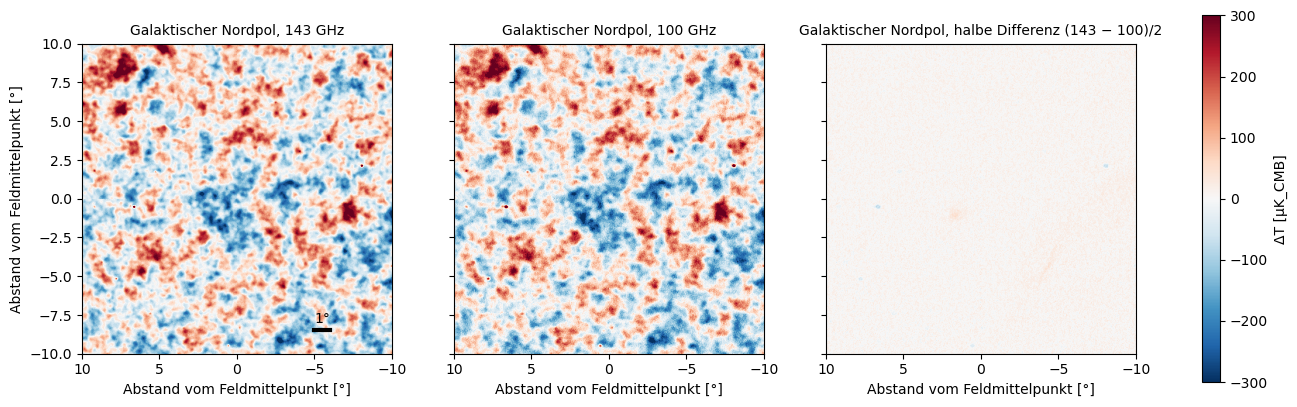

Nordpol        : Streuung 143 GHz 101.8 μK, 100 GHz 101.0 μK, halbe Differenz 11.2 μK, Korrelation 0.9756
Südpol         : Streuung 143 GHz 101.6 μK, 100 GHz 100.8 μK, halbe Differenz 11.1 μK, Korrelation 0.9761
Nord, l = 150° : Streuung 143 GHz  97.6 μK, 100 GHz  96.3 μK, halbe Differenz  9.8 μK, Korrelation 0.9797
Süd, l = 210°  : Streuung 143 GHz 112.9 μK, 100 GHz 112.9 μK, halbe Differenz 12.7 μK, Korrelation 0.9745


In [3]:
ext = [SIZE / 2, -SIZE / 2, -SIZE / 2, SIZE / 2]
a, b = MAPS["Nordpol"]["143"], MAPS["Nordpol"]["100"]
fig, axs = plt.subplots(1, 3, figsize=(17, 5.6), sharey=True)
for ax, img, title in zip(axs, [a - a.mean(), b - b.mean(), (a - b) / 2],
                          ["143 GHz", "100 GHz", "halbe Differenz (143 − 100)/2"]):
    im = ax.imshow(img, origin="lower", extent=ext, cmap="RdBu_r", vmin=-300, vmax=300)
    ax.set_title(f"Galaktischer Nordpol, {title}", fontsize=10)
    ax.set_xlabel("Abstand vom Feldmittelpunkt [°]")
axs[0].set_ylabel("Abstand vom Feldmittelpunkt [°]")
axs[0].plot([-6, -5], [-8.5, -8.5], color="k", lw=3)
axs[0].text(-5.5, -8, "1°", ha="center", fontsize=10)
fig.colorbar(im, ax=axs, shrink=0.85, label="ΔT [μK_CMB]")
plt.show()

for name, m in MAPS.items():
    a, b = m["143"] - m["143"].mean(), m["100"] - m["100"].mean()
    r = np.corrcoef(a.ravel(), b.ravel())[0, 1]
    print(f"{name:15s}: Streuung 143 GHz {a.std():5.1f} μK, 100 GHz {b.std():5.1f} μK, "
          f"halbe Differenz {((a - b) / 2).std():4.1f} μK, Korrelation {r:.4f}")

* Drei Bilder desselben Feldes am galaktischen Nordpol, 20° × 20°, Farben von −300 bis +300 μK. Bei 143 und 100 GHz sieht man dieselben Flecken: warme (rot) und kalte (blau) Gebiete von etwa 1° und darin kleinere von einigen Bogenminuten. Der schwarze Balken ist 1° lang, so viel wie zwei Vollmonde.
* Die Karten streuen um 96 bis 113 μK, die halbe Differenz nur um 10 bis 13 μK, und die beiden Frequenzen sind zu 0.975 bis 0.980 korreliert. Die Flecken haben also bei beiden Frequenzen dieselbe Stärke in K_CMB. Das ist das Kennzeichen der Hintergrundstrahlung (Theorie, Abschnitt 1); Rauschen oder Staub wären in den beiden Karten verschieden.
* Zur Vorhersage: Die halbe Differenz ist etwa zehnmal schwächer als die Karten. Darin bleiben vor allem das Rauschen und der breitere Strahl bei 100 GHz übrig, deshalb ist die Korrelation nicht ganz 1. Die einzelnen Punkte in der Differenz sind Quellen, deren Helligkeit sich mit der Frequenz anders ändert als die der Hintergrundstrahlung (Schritt 4).

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-2"></a>

##### *2. Das Leistungsspektrum von Planck*

Wie sieht das veröffentlichte Leistungsspektrum aus, wie viele Peaks zeigt es, und wo liegen sie ungefähr? Vorher vorhersagen: Wenn die Flecken in Schritt 1 typisch 1° groß sind, bei welchem ℓ liegt dann der erste Peak?

Der Code zeichnet das Spektrum von Planck für jedes einzelne ℓ (grau), dasselbe in Bins (schwarz) und das beste ΛCDM-Modell (rot). Darunter steht die Abweichung der Bins vom Modell in Einheiten ihres Fehlers. Er gibt das Maximum, den Quadrupol ℓ = 2 und das χ² der Bins gegen das Modell aus.

**Hintergrund & Fachbegriffe:**
- **Bins:** Mittelwerte über benachbarte ℓ; sie sind viel genauer als einzelne ℓ, verwischen aber feine Strukturen.
- **Quadrupol:** ℓ = 2, die größte Struktur nach dem Dipol (ℓ = 1, der von unserer Bewegung gegen die Hintergrundstrahlung kommt und abgezogen ist). Bei kleinen ℓ ist die kosmische Varianz groß (Theorie, Abschnitt 2), die Fehler sind dort unsymmetrisch.
- **χ² pro Freiheitsgrad:** Summe der quadrierten Abweichungen in Fehlereinheiten, geteilt durch die Zahl der Punkte; etwa 1 heißt, das Modell beschreibt die Daten im Rahmen der Fehler.

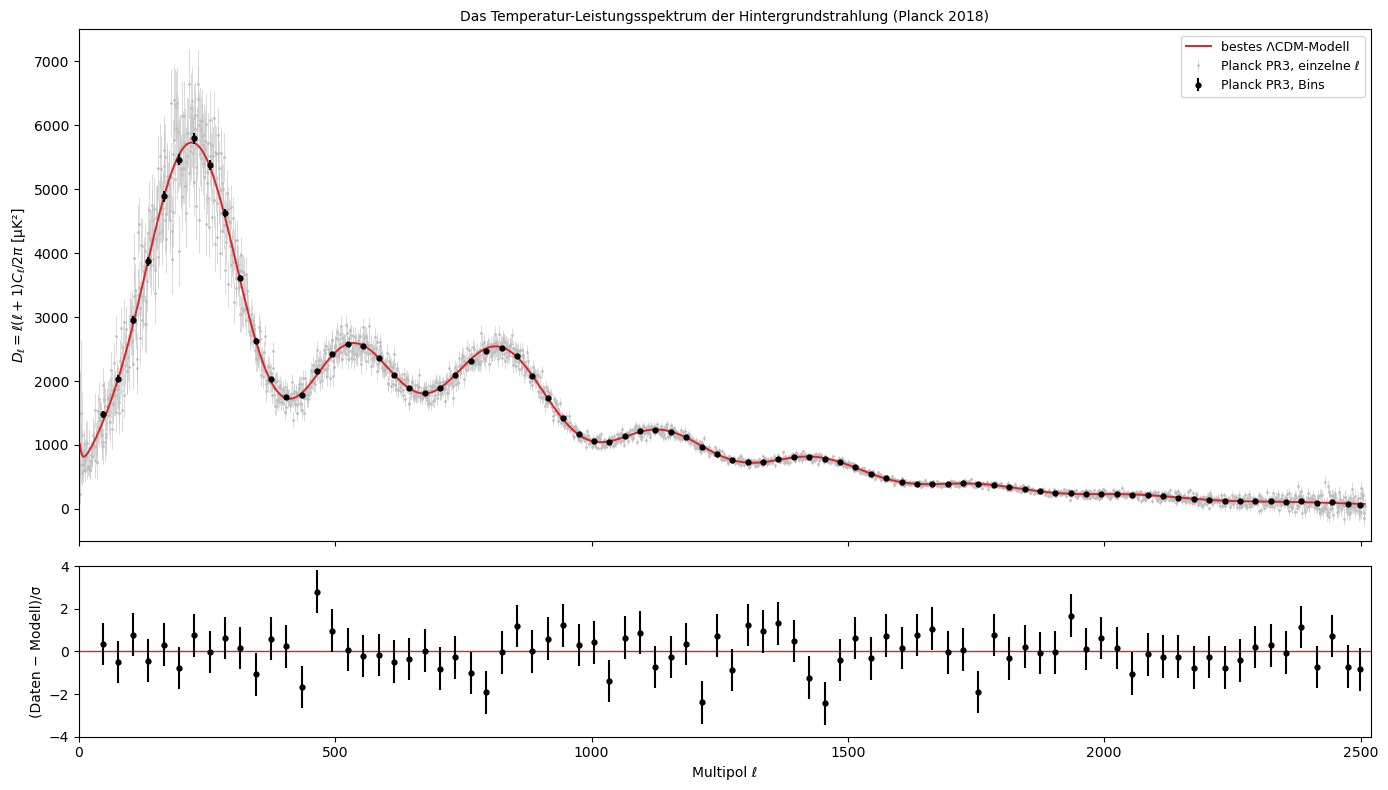

höchster Bin: ℓ = 225, D = 5793 μK²; das entspricht Flecken von etwa 0.80°
Quadrupol ℓ = 2: gemessen 226 (−132/+533) μK², Modell 1017 μK²
Bins gegen bestes Modell: χ² = 65.1 bei 83 Bins (χ²/N = 0.78)


In [4]:
lb, db, eb, dbm = BINNED[:, 0], BINNED[:, 1], (BINNED[:, 2] + BINNED[:, 3]) / 2, BINNED[:, 4]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax.errorbar(L, DL, yerr=[FULL[:, 2], FULL[:, 3]], fmt=".", ms=2, color="0.75", elinewidth=0.4, zorder=1,
            label="Planck PR3, einzelne ℓ")
ax.errorbar(lb, db, yerr=eb, fmt="o", ms=3.5, color="k", zorder=3, label="Planck PR3, Bins")
ax.plot(LT[LT <= 2508], DT[LT <= 2508], color="C3", lw=1.4, zorder=2, label="bestes ΛCDM-Modell")
ax.set_ylim(-500, 7500)
ax.set_ylabel(r"$D_\ell = \ell(\ell+1)C_\ell/2\pi$ [μK²]")
ax.set_title("Das Temperatur-Leistungsspektrum der Hintergrundstrahlung (Planck 2018)", fontsize=10)
ax.legend(fontsize=9)
ax2.axhline(0, color="C3", lw=1)
ax2.errorbar(lb, (db - dbm) / eb, yerr=1, fmt="o", ms=3.5, color="k")
ax2.set_ylim(-4, 4)
ax2.set_xlabel("Multipol ℓ")
ax2.set_ylabel("(Daten − Modell)/σ")
ax2.set_xlim(0, 2520)
plt.tight_layout()
plt.show()

i = np.argmax(db)
chi2 = np.sum(((db - dbm) / eb) ** 2)
print(f"höchster Bin: ℓ = {lb[i]:.0f}, D = {db[i]:.0f} μK²; das entspricht Flecken von etwa {180 / lb[i]:.2f}°")
print(f"Quadrupol ℓ = 2: gemessen {DL[0]:.0f} (−{FULL[0, 2]:.0f}/+{FULL[0, 3]:.0f}) μK², Modell {d_theory(2):.0f} μK²")
print(f"Bins gegen bestes Modell: χ² = {chi2:.1f} bei {len(lb)} Bins (χ²/N = {chi2 / len(lb):.2f})")

* Grau das Spektrum für jedes einzelne ℓ, schwarz die Bins, rot das beste ΛCDM-Modell. Man sieht den hohen ersten Peak, vier weitere deutliche Peaks bis ℓ ≈ 1500 und darüber den Dämpfungsschwanz, in dem sich noch zwei flache Wellen andeuten. Unten steht die Abweichung der Bins vom Modell; sie streut um null.
* Der höchste Bin liegt bei ℓ = 225 mit 5793 μK², das entspricht Flecken von etwa 0.8°. Das χ² der 83 Bins gegen das Modell ist 65.1 (χ²/N = 0.78): Ein Modell mit sechs Parametern beschreibt 2500 Multipole im Rahmen der Fehler.
* Zur Vorhersage: Flecken von 1° gehören nach der Faustregel zu ℓ ≈ 180; der Peak liegt bei 220, weil ℓ ≈ 180°/θ nur grob gilt. Der Quadrupol ℓ = 2 ist mit 226 μK² viel kleiner als im Modell (1017 μK²). Wegen der kosmischen Varianz ist das aber nur eine Abweichung von etwa 1.5σ (Fehler −132/+533).

[↑ Zurück zur Landkarte](#landkarte)

#### **Reduktion**

<a id="exp-3"></a>

##### *3. Strahl, Pixel und Rauschen*

Wie viel der gemessenen Leistung in einem Feld kommt vom Himmel, wie viel vom Rauschen, und wie stark dämpfen Strahl und Pixel die kleinen Skalen? Vorher vorhersagen: Bei welchem ℓ ist die Leistung der 143-GHz-Karte durch den Strahl auf die Hälfte gedämpft?

Der Code rechnet für das Feld am Nordpol links die Dämpfung $B_\ell^2$ durch Strahl und Pixel für beide Frequenzen. Rechts stehen die Spektren:
- die Karte bei 143 GHz ohne Korrektur,
- dieselbe korrigiert, also geteilt durch Strahl und Pixelfenster,
- die korrigierte Karte bei 100 GHz,
- das korrigierte Kreuzspektrum 100 × 143,
- die halbe Differenz, korrigiert wie die 143-GHz-Karte. Sie zeigt, was Rauschen und Vordergründe zum Spektrum einer einzelnen Karte beitragen.

**Hintergrund & Fachbegriffe:**
- **Pixelfenster:** Ein Pixel mittelt über seine Fläche und dämpft dadurch Wellen, die kürzer als einige Pixel sind. Hier wirken zwei Pixel nacheinander: das HEALPix-Pixel von 1.7′ und das 3′-Pixel von SkyView.
- **Rauschbias:** Das Spektrum einer einzelnen Karte enthält das Spektrum ihres Rauschens zusätzlich zum Himmel. Nach dem Teilen durch $B_\ell^2$ wächst es bei hohen ℓ stark an; das Kreuzspektrum hat diesen Bias nicht (Theorie, Abschnitt 2).

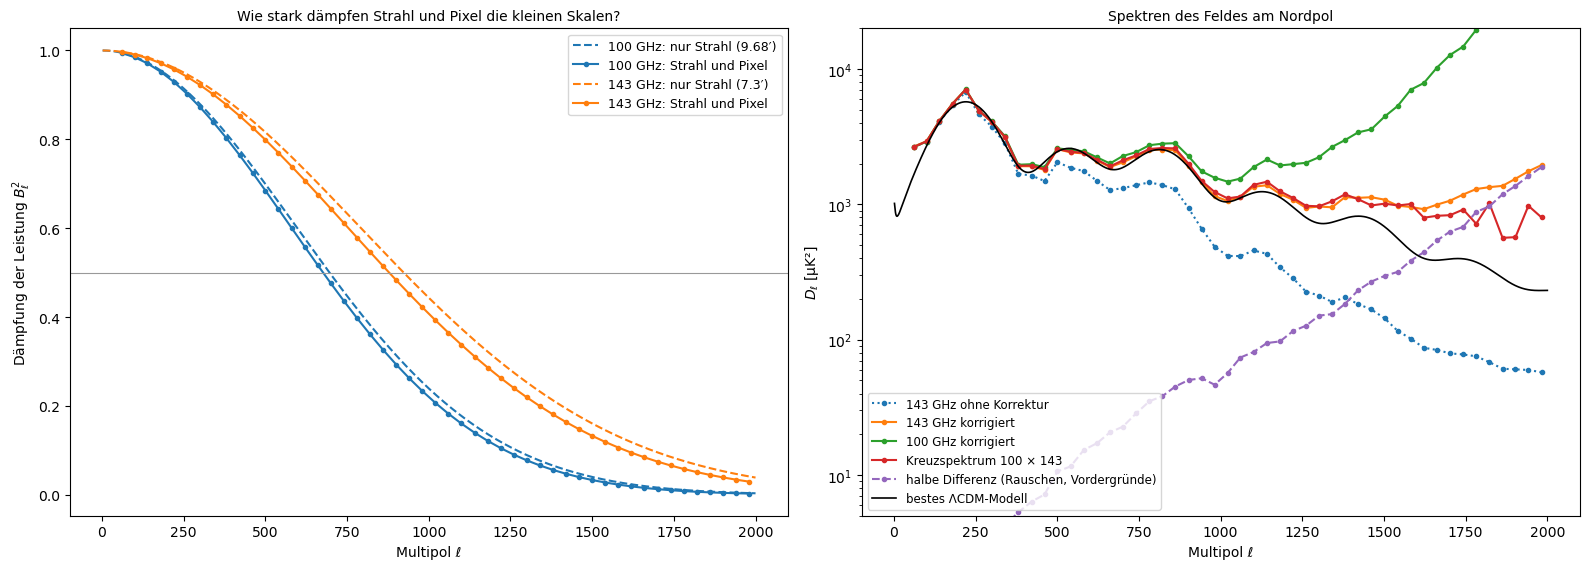

Strahl allein halbiert die Leistung bei ℓ = 696 (100 GHz) und ℓ = 923 (143 GHz)
ℓ ≈  501: 143 korrigiert   2560, Kreuz   2562, halbe Differenz     11, Modell  2451 μK²
ℓ ≈  982: 143 korrigiert   1152, Kreuz   1234, halbe Differenz     46, Modell  1126 μK²
ℓ ≈ 1502: 143 korrigiert   1083, Kreuz   1012, halbe Differenz    296, Modell   682 μK²
ℓ ≈ 1902: 143 korrigiert   1546, Kreuz    572, halbe Differenz   1369, Modell   251 μK²


In [5]:
m = MAPS["Nordpol"]
lx, ly, ell = ell_grid()
ells = np.arange(2, 2001)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))
for f, c in [("100", "C0"), ("143", "C1")]:
    ax.plot(ells, gauss_beam(ells, FWHM[f]) ** 2, color=c, ls="--", label=f"{f} GHz: nur Strahl ({FWHM[f]}′)")
    i = np.digitize(ell.ravel(), EDGES) - 1
    ok = (i >= 0) & (i < len(EDGES) - 1)
    t2 = np.bincount(i[ok], transfer(f, lx, ly, ell).ravel()[ok] ** 2) / np.bincount(i[ok])
    lb = np.bincount(i[ok], ell.ravel()[ok]) / np.bincount(i[ok])
    ax.plot(lb, t2, "o-", ms=3, color=c, label=f"{f} GHz: Strahl und Pixel")
ax.axhline(0.5, color="0.6", lw=0.8)
ax.set_xlabel("Multipol ℓ")
ax.set_ylabel(r"Dämpfung der Leistung $B_\ell^2$")
ax.set_title("Wie stark dämpfen Strahl und Pixel die kleinen Skalen?", fontsize=10)
ax.legend(fontsize=9)
spec = {"143 GHz ohne Korrektur": spectrum(m["143"], m["143"]),
        "143 GHz korrigiert": spectrum(m["143"], m["143"], "143", "143"),
        "100 GHz korrigiert": spectrum(m["100"], m["100"], "100", "100"),
        "Kreuzspektrum 100 × 143": spectrum(m["100"], m["143"], "100", "143"),
        "halbe Differenz (Rauschen, Vordergründe)": spectrum((m["143"] - m["100"]) / 2, (m["143"] - m["100"]) / 2, "143", "143")}
for (k, (lb, d)), st in zip(spec.items(), [":", "-", "-", "-", "--"]):
    ax2.plot(lb, np.abs(d), st, marker="o", ms=3, label=k)
ax2.plot(ells, d_theory(ells), color="k", lw=1.2, label="bestes ΛCDM-Modell")
ax2.set_yscale("log")
ax2.set_ylim(5, 2e4)
ax2.set_xlabel("Multipol ℓ")
ax2.set_ylabel(r"$D_\ell$ [μK²]")
ax2.set_title("Spektren des Feldes am Nordpol", fontsize=10)
ax2.legend(fontsize=8.5, loc="lower left")
plt.tight_layout()
plt.show()

half = {f: ells[np.argmin(np.abs(gauss_beam(ells, FWHM[f]) ** 2 - 0.5))] for f in FWHM}
print(f"Strahl allein halbiert die Leistung bei ℓ = {half['100']} (100 GHz) und ℓ = {half['143']} (143 GHz)")
lb = spec["143 GHz korrigiert"][0]
for target in (500, 1000, 1500, 1900):
    k = np.argmin(np.abs(lb - target))
    n = spec["halbe Differenz (Rauschen, Vordergründe)"][1][k]
    print(f"ℓ ≈ {lb[k]:4.0f}: 143 korrigiert {spec['143 GHz korrigiert'][1][k]:6.0f}, Kreuz {spec['Kreuzspektrum 100 × 143'][1][k]:6.0f}, "
          f"halbe Differenz {n:6.0f}, Modell {d_theory(lb[k]):5.0f} μK²")

* Links die Dämpfung der Leistung durch den Strahl allein (gestrichelt) und durch Strahl und beide Pixel (Punkte). Die Pixel nehmen bei ℓ = 1000 noch einmal 5 bis 10 % weg. Bei ℓ = 2000 ist von der Leistung bei 100 GHz weniger als 1 % übrig, bei 143 GHz etwa 3 %.
* Rechts die Spektren des Feldes am Nordpol. Ohne Korrektur (blau gepunktet) fällt das Spektrum ab ℓ ≈ 500 weit unter das Modell. Nach der Korrektur folgen 143 GHz, 100 GHz und das Kreuzspektrum dem Modell bis ℓ ≈ 1000; bei ℓ ≈ 500 liegen 143 GHz und das Kreuzspektrum mit 2560 und 2562 μK² nahe am Modell (2451). Darüber trennen sie sich. Die halbe Differenz zeigt, dass das Rauschen bei ℓ ≈ 1500 schon 296 μK² beiträgt und bei 1900 mit 1369 μK² mehr als das Signal (251). Das Kreuzspektrum hat keinen Rauschbias und liegt bei 1900 mit 572 μK² am nächsten am Modell; der Rest sind Punktquellen (Schritt 4).
* Zur Vorhersage: Der Strahl allein halbiert die Leistung bei ℓ = 923 (143 GHz) und schon bei ℓ = 696 (100 GHz). Das 100-GHz-Spektrum steigt deshalb nach der Korrektur am stärksten an: Sein Rauschen wird am meisten verstärkt.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-4"></a>

##### *4. Punktquellen*

Welche hellen Punktquellen stecken in den Feldern, und wie viel tragen sie zur Leistung bei kleinen Skalen bei? Vorher vorhersagen: Wächst der Beitrag von Punktquellen in $D_\ell$ mit ℓ, oder fällt er wie das Spektrum der Hintergrundstrahlung?

Der Code sucht in jedem Feld und bei beiden Frequenzen nach Quellen. Dafür zieht er von der Karte eine auf 30′ geglättete Fassung ab, sodass die großen Flecken der Hintergrundstrahlung verschwinden. Dann glättet er mit dem Strahl, was ein einfacher **Matched Filter** ist, und nimmt jedes Maximum über 5 robusten Standardabweichungen. Jede Quelle ersetzt er in beiden Karten in einem Kreis von 12′ durch den Median eines Rings darum (**Inpainting**). Links steht das gefilterte Feld mit den gefundenen Quellen, rechts das Kreuzspektrum aller vier Felder vor und nach dem Ersetzen, geteilt durch das Modell.

**Hintergrund & Fachbegriffe:**
- **Punktquellen:** Bei 100 und 143 GHz sind das vor allem Radiogalaxien und Quasare (Synchrotronstrahlung aus Jets) und bei höheren Frequenzen staubige Galaxien. Sie sind kleiner als der Strahl und erscheinen deshalb mit seiner Form.
- **Poisson-Rauschen der Quellen:** Zufällig verteilte Punktquellen haben ein flaches $C_\ell$, also $D_\ell \propto \ell^2$. Bei kleinen ℓ fallen sie nicht auf, bei großen ℓ übertreffen sie die gedämpfte Hintergrundstrahlung.
- **Robuste Standardabweichung:** 1.4826 × Median der absoluten Abweichungen vom Median; sie wird von den wenigen hellen Quellen selbst kaum verfälscht.

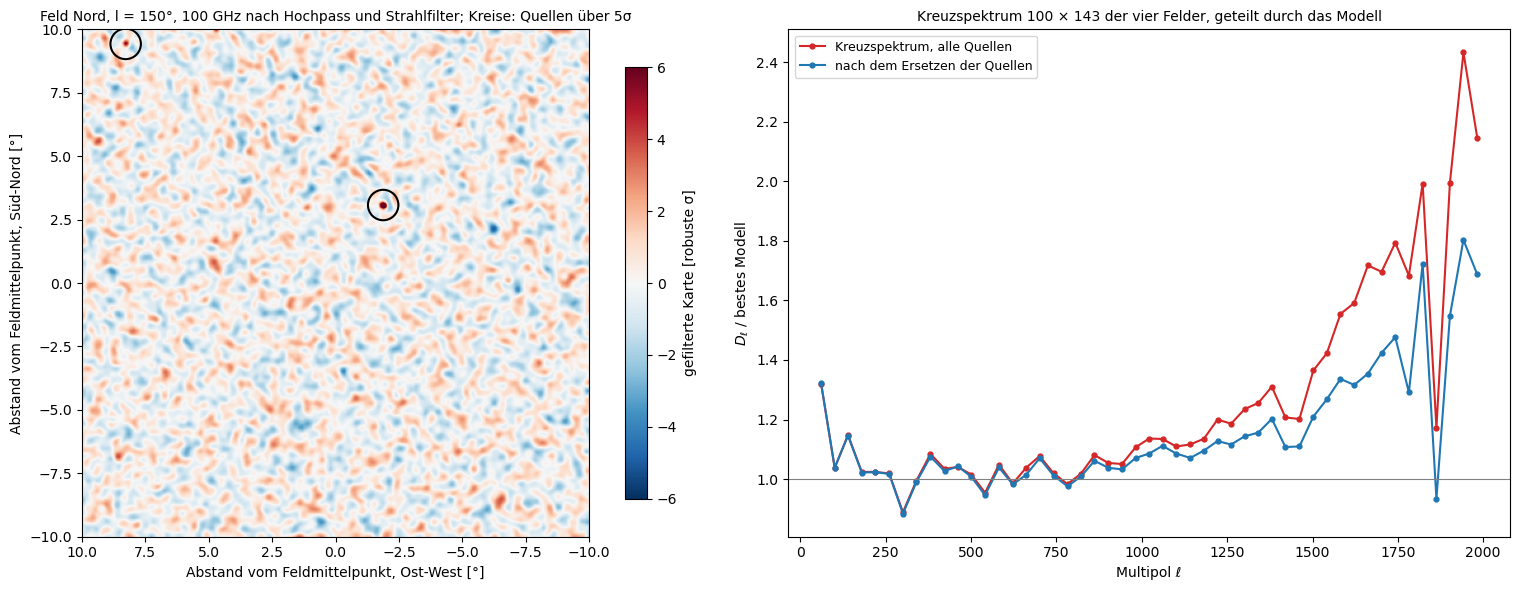

Nordpol        : 3 Quellen; Spitzen bei 100 / 143 GHz [μK]: 571/452, 584/477, 331/317
Südpol         : 3 Quellen; Spitzen bei 100 / 143 GHz [μK]: 468/413, 362/287, 481/543
Nord, l = 150° : 2 Quellen; Spitzen bei 100 / 143 GHz [μK]: 884/777, 333/312
Süd, l = 210°  : 1 Quellen; Spitzen bei 100 / 143 GHz [μK]: 412/444
ℓ ≈  501: Kreuzspektrum / Modell 1.02 mit Quellen, 1.01 ohne
ℓ ≈  982: Kreuzspektrum / Modell 1.11 mit Quellen, 1.07 ohne
ℓ ≈ 1502: Kreuzspektrum / Modell 1.36 mit Quellen, 1.21 ohne
ℓ ≈ 1902: Kreuzspektrum / Modell 2.00 mit Quellen, 1.55 ohne


In [6]:
def find_sources(m, freq, nsig=5.0):
    # Hochpass (Karte minus Glättung auf 30′), dann Glättung mit dem Strahl; Maxima über nsig robusten σ
    hp = m - ndimage.gaussian_filter(m, 30 / 3 / 2.355)
    mf = ndimage.gaussian_filter(hp, FWHM[freq] / 3 / 2.355)
    snr = mf / (1.4826 * np.median(np.abs(mf - np.median(mf))))
    lab, n = ndimage.label(snr > nsig)
    return [tuple(p) for p in ndimage.maximum_position(snr, lab, range(1, n + 1))], snr


def inpaint(m, pos, r=4, r2=7):
    # Kreis mit Radius r Pixel (12′) durch den Median des Rings r bis r2 ersetzen
    out = m.copy()
    yy, xx = np.mgrid[:m.shape[0], :m.shape[1]]
    for y, x in pos:
        d = np.hypot(yy - y, xx - x)
        out[d < r] = np.median(m[(d >= r) & (d < r2)])
    return out


SOURCES, CLEAN = {}, {}
for name, m in MAPS.items():
    pos = sorted(set(find_sources(m["100"], "100")[0]) | set(find_sources(m["143"], "143")[0]))
    SOURCES[name] = pos
    CLEAN[name] = {f: inpaint(m[f], pos) for f in FWHM}


def field_mean(maps, fa, fb):
    lb = spectrum(maps["Nordpol"][fa], maps["Nordpol"][fb], fa, fb)[0]
    return lb, np.mean([spectrum(maps[n][fa], maps[n][fb], fa, fb)[1] for n in maps], axis=0)


lb, x_raw = field_mean(MAPS, "100", "143")
_, x_clean = field_mean(CLEAN, "100", "143")
show = "Nord, l = 150°"
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 6))
snr = find_sources(MAPS[show]["100"], "100")[1]
im = ax.imshow(snr, origin="lower", extent=ext, cmap="RdBu_r", vmin=-6, vmax=6)
for y, x in SOURCES[show]:
    ax.add_patch(plt.Circle((SIZE / 2 - (x + 0.5) * SIZE / NPIX, (y + 0.5) * SIZE / NPIX - SIZE / 2), 0.6, fill=False, color="k", lw=1.5))
fig.colorbar(im, ax=ax, shrink=0.85, label="gefilterte Karte [robuste σ]")
ax.set_xlabel("Abstand vom Feldmittelpunkt, Ost-West [°]")
ax.set_ylabel("Abstand vom Feldmittelpunkt, Süd-Nord [°]")
ax.set_title(f"Feld {show}, 100 GHz nach Hochpass und Strahlfilter; Kreise: Quellen über 5σ", fontsize=10)
ax2.plot(lb, x_raw / d_theory(lb), "o-", ms=3.5, color="C3", label="Kreuzspektrum, alle Quellen")
ax2.plot(lb, x_clean / d_theory(lb), "o-", ms=3.5, color="C0", label="nach dem Ersetzen der Quellen")
ax2.axhline(1, color="0.5", lw=0.8)
ax2.set_xlabel("Multipol ℓ")
ax2.set_ylabel(r"$D_\ell$ / bestes Modell")
ax2.set_title("Kreuzspektrum 100 × 143 der vier Felder, geteilt durch das Modell", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for name, pos in SOURCES.items():
    print(f"{name:15s}: {len(pos)} Quellen; Spitzen bei 100 / 143 GHz [μK]: " +
          ", ".join(f"{MAPS[name]['100'][p] - np.median(MAPS[name]['100']):.0f}/{MAPS[name]['143'][p] - np.median(MAPS[name]['143']):.0f}" for p in pos))
for target in (500, 1000, 1500, 1900):
    k = np.argmin(np.abs(lb - target))
    print(f"ℓ ≈ {lb[k]:4.0f}: Kreuzspektrum / Modell {x_raw[k] / d_theory(lb[k]):.2f} mit Quellen, {x_clean[k] / d_theory(lb[k]):.2f} ohne")

* Links das Feld „Nord, l = 150°“ bei 100 GHz nach dem Filter, in Einheiten der robusten Streuung. Die Hintergrundstrahlung ist zu einem feinen Muster von etwa ±2σ geworden, die beiden Quellen stechen mit über 5σ heraus (Kreise). In allen vier Feldern findet der Filter neun Quellen mit Spitzen von 290 bis 880 μK.
* Rechts das Kreuzspektrum der vier Felder, geteilt durch das Modell, rot mit und blau ohne die Quellen. Bis ℓ ≈ 800 ändert sich nichts. Bei ℓ = 1500 fällt das Verhältnis von 1.36 auf 1.21, bei 1900 von 2.00 auf 1.55. Die neun hellsten Quellen machen also etwa 40 % des Überschusses aus. Den Rest schreibe ich schwächeren Quellen unter der Schwelle und dem infraroten Hintergrund staubiger Galaxien zu; das ist eine Abschätzung aus der Größenordnung, keine eigene Messung.
* Zur Vorhersage: Punktquellen haben ein flaches $C_\ell$, also $D_\ell \propto \ell^2$. Ihr Beitrag wächst mit ℓ, während die Hintergrundstrahlung abfällt. Deshalb bekommt der Fit in Schritt 6 einen Term $P(\ell/1500)^2$.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-5"></a>

##### *5. Kosmische Varianz und ein Test des Verfahrens*

Wie genau lässt sich $D_\ell$ überhaupt messen? Und gibt das Verfahren aus Schritt 3 bei einer Karte mit bekanntem Spektrum das richtige Spektrum zurück? Vorher vorhersagen: Welchen Anteil des Himmels nutzt Planck wirksam, wenn die Fehler bei mittleren ℓ das 1.4-Fache der kosmischen Varianz für den ganzen Himmel sind?

Links teilt der Code die Fehler von Planck durch die kosmische Varianz für den ganzen Himmel (Theorie, Abschnitt 2). Daraus folgt der wirksame Himmelsanteil $f_\text{sky} = 2/[(2\ell+1)(\sigma/D)^2]$: Ist er so groß wie der genutzte Himmel, begrenzt die kosmische Varianz die Messung; fällt er ab, begrenzt das Rauschen.

Rechts erzeugt er 24 simulierte Felder mit dem Spektrum des besten Modells. Sie sind mit Strahl und Pixeln gefaltet wie die echten Karten und kommen aus einem dreimal größeren Feld, damit auch Wellen größer als das Feld darin stecken. Für sie rechnet er das Kreuzspektrum genau wie in Schritt 3. Er zeigt:
- den Mittelwert geteilt durch das Eingangsspektrum (muss 1 sein),
- die Streuung von Feld zu Feld neben der Erwartung aus der kosmischen Varianz eines 20°-Feldes.

**Hintergrund & Fachbegriffe:**
- **Wirksamer Himmelsanteil:** der Anteil des Himmels, den eine Messung ohne Rauschen haben müsste, um dieselben Fehler zu erreichen; Planck maskiert die Milchstraße und helle Quellen und behält je nach Frequenz etwa die Hälfte bis zwei Drittel des Himmels.
- **Erwartungstreue:** Ein Verfahren ist erwartungstreu, wenn sein Mittelwert über viele Realisierungen den wahren Wert trifft; das ist die Grundlinie, bevor man den echten Daten traut.
- **Moden im Ring:** Ein Ring der Breite Δℓ in der Fourier-Ebene eines Feldes mit Fläche A enthält ℓ Δℓ A/2π unabhängige Wellen; ihre Zahl legt die Streuung fest, $\sigma/D = \sqrt{2/N}$.

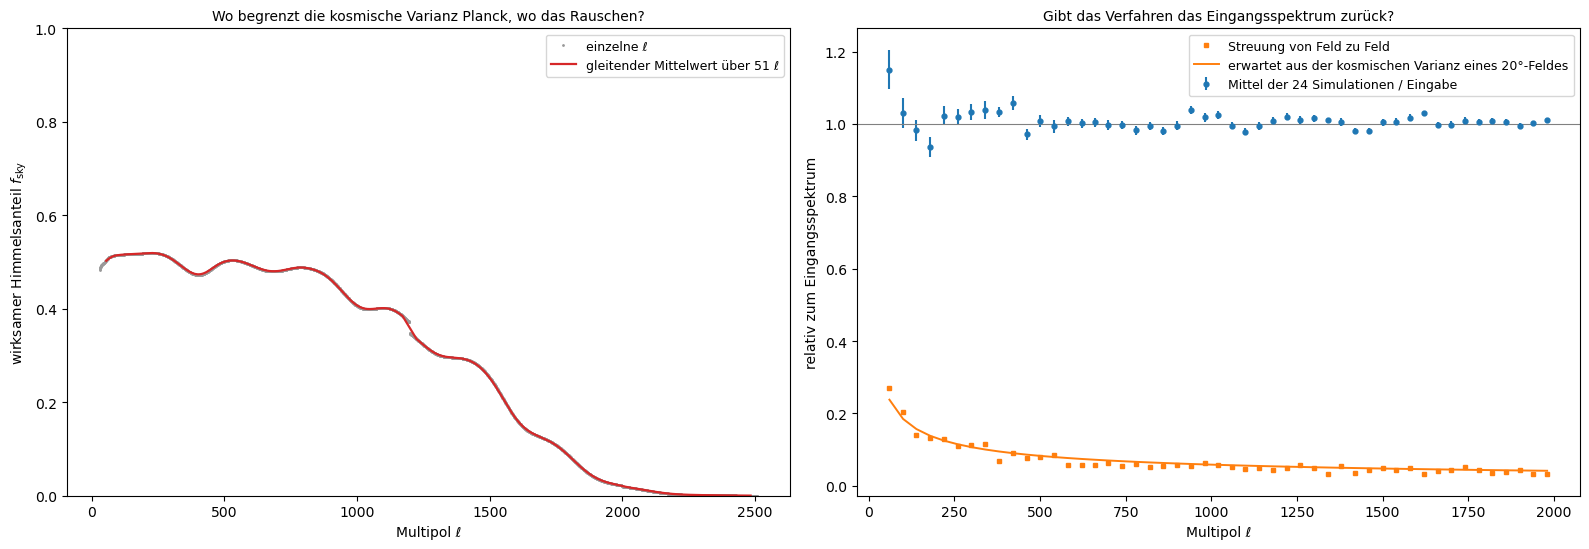

Planck ℓ =   30– 800: Fehler / kosmische Varianz  1.42, f_sky = 0.50
Planck ℓ =  800–1300: Fehler / kosmische Varianz  1.58, f_sky = 0.40
Planck ℓ = 1300–1800: Fehler / kosmische Varianz  2.19, f_sky = 0.21
Planck ℓ = 1800–2508: Fehler / kosmische Varianz 13.04, f_sky = 0.01
Simulationen ℓ =   40– 400: Mittel/Eingabe 1.027 ± 0.011, Streuung/erwartet 1.00
Simulationen ℓ =  400–1200: Mittel/Eingabe 1.003 ± 0.003, Streuung/erwartet 0.89
Simulationen ℓ = 1200–2000: Mittel/Eingabe 1.006 ± 0.002, Streuung/erwartet 0.92
wirksamer Himmelsanteil eines Feldes: 0.0073


In [7]:
rng = np.random.default_rng(42)
N_SIM = 24
lb = spectrum(MAPS["Nordpol"]["100"], MAPS["Nordpol"]["143"], "100", "143", sky=False)[0]
sims = np.array([spectrum(s["100"], s["143"], "100", "143", sky=False)[1] for s in (simulate(rng) for _ in range(N_SIM))])
ratio = sims / d_theory(lb)
w2, w4 = np.mean(WINDOW**2), np.mean(WINDOW**4)
n_ring = lb * np.diff(EDGES) * np.radians(SIZE) ** 2 / (2 * np.pi) * w2**2 / w4   # unabhängige Wellen pro Ring
expect = np.sqrt(2 / n_ring)

fsky_planck = 2 / ((2 * L + 1) * (ERR / d_theory(L)) ** 2)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.plot(L[L >= 30], fsky_planck[L >= 30], ".", ms=2, color="0.6", label="einzelne ℓ")
k = np.convolve(fsky_planck[L >= 30], np.ones(51) / 51, mode="same")
ax.plot(L[L >= 30][25:-25], k[25:-25], color="C3", lw=1.6, label="gleitender Mittelwert über 51 ℓ")
ax.set_ylim(0, 1)
ax.set_xlabel("Multipol ℓ")
ax.set_ylabel(r"wirksamer Himmelsanteil $f_\mathrm{sky}$")
ax.set_title("Wo begrenzt die kosmische Varianz Planck, wo das Rauschen?", fontsize=10)
ax.legend(fontsize=9)
ax2.errorbar(lb, ratio.mean(0), yerr=ratio.std(0) / np.sqrt(N_SIM), fmt="o", ms=3.5, color="C0",
             label=f"Mittel der {N_SIM} Simulationen / Eingabe")
ax2.plot(lb, ratio.std(0), "s", ms=3.5, color="C1", label="Streuung von Feld zu Feld")
ax2.plot(lb, expect, color="C1", lw=1.4, label="erwartet aus der kosmischen Varianz eines 20°-Feldes")
ax2.axhline(1, color="0.5", lw=0.8)
ax2.set_xlabel("Multipol ℓ")
ax2.set_ylabel(r"relativ zum Eingangsspektrum")
ax2.set_title("Gibt das Verfahren das Eingangsspektrum zurück?", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

for lo, hi in [(30, 800), (800, 1300), (1300, 1800), (1800, 2508)]:
    s = (L >= lo) & (L < hi)
    print(f"Planck ℓ = {lo:4d}–{hi:4d}: Fehler / kosmische Varianz {np.median(ERR[s] / d_theory(L[s]) * np.sqrt((2 * L[s] + 1) / 2)):5.2f}, "
          f"f_sky = {np.median(fsky_planck[s]):.2f}")
for lo, hi in [(40, 400), (400, 1200), (1200, 2000)]:
    s = (lb >= lo) & (lb < hi)
    print(f"Simulationen ℓ = {lo:4d}–{hi:4d}: Mittel/Eingabe {ratio[:, s].mean():.3f} ± {ratio[:, s].mean(1).std() / np.sqrt(N_SIM):.3f}, "
          f"Streuung/erwartet {np.mean(ratio[:, s].std(0) / expect[s]):.2f}")
print(f"wirksamer Himmelsanteil eines Feldes: {np.radians(SIZE) ** 2 * w2**2 / w4 / (4 * np.pi):.4f}")

* Links der wirksame Himmelsanteil von Planck. Bis ℓ ≈ 800 liegt er bei 0.50, die Fehler sind dort das 1.42-Fache der kosmischen Varianz des ganzen Himmels. Zwischen 800 und 1300 liegt er bei 0.40, darüber fällt er schnell auf 0.01 bei ℓ > 1800. Bis ℓ ≈ 1000 begrenzt also die kosmische Varianz die Messung, darüber begrenzen sie Rauschen und Strahl. Die Wellen der Kurve kommen daher, dass das Rauschen in den Tälern des Spektrums mehr zählt als auf den Peaks.
* Rechts die 24 Simulationen. Ihr Mittel trifft das Eingangsspektrum von ℓ = 400 bis 2000 auf 0.3 bis 0.6 % (1.003 ± 0.003 und 1.006 ± 0.002). Unter ℓ = 400 liegt es 2.7 ± 1.1 % zu hoch, weil das Fenster dort Wellen mischt, die kaum kleiner als das Feld sind. Die Streuung von Feld zu Feld ist das 0.89- bis 1.00-Fache der Erwartung. Das Verfahren ist also erwartungstreu, und die Fehler in Schritt 6 haben die richtige Größe. Eine Grenze hat dieser Test: Er prüft das Verfahren, nicht die Karten. Die Lücken, die SkyView an den Polen lässt, kommen in den Simulationen nicht vor (siehe Variationen).
* Zur Vorhersage: f_sky = 1/1.42² = 0.50. Ein Feld von 20° hat wirksam f_sky = 0.0073, vier Felder 0.03, etwa siebzehnmal weniger als Planck. Die eigenen Fehler sind deshalb etwa viermal größer.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung**

<a id="exp-6"></a>

##### *6. Das eigene Spektrum aus vier Feldern*

Findet man die akustischen Peaks auch selbst in den Karten, und wie gut passt das eigene Spektrum zu dem von Planck? Vorher vorhersagen: Wie viele Peaks sollten in vier Feldern von 20° zu sehen sein, wenn Strahl und Rauschen ab ℓ ≈ 1500 stören?

Der Code mittelt das Kreuzspektrum 100 × 143 der vier Felder ohne die Punktquellen aus Schritt 4. Den Fehler jedes Bins schätzt er aus den Spektren der beiden Frequenzen, die das Rauschen enthalten, und der Zahl der Wellen im Ring:

$$\sigma^2 = \frac{D^{100\times100}\,D^{143\times143} + (D^{100\times143})^2}{4\,N_\text{Ring}}.$$

Dann passt er bis ℓ = 1200 drei Zahlen an:

$$D_\ell = A\, D^\text{Modell}_{\alpha\ell} + P \left(\frac{\ell}{1500}\right)^2 .$$

Darin ist $A$ die Amplitude (Kalibration), $P$ die Leistung der übrigen Punktquellen bei ℓ = 1500 und $\alpha$ eine Streckung des Spektrums entlang ℓ. Stimmt der Winkel des Schallhorizonts in den eigenen Feldern mit dem des besten Modells überein, ist $\alpha = 1$; sonst ist $\theta_\star^\text{eigen} = \alpha\,\theta_\star^\text{Modell}$ (Theorie, Abschnitt 3; Schritt 10 macht denselben Fit mit dem Spektrum von Planck).

**Hintergrund & Fachbegriffe:**
- **Knox-Formel:** die Varianz eines gemessenen Spektrums aus kosmischer Varianz und Rauschen; für ein Kreuzspektrum gehen die beiden Einzelspektren und das Kreuzspektrum selbst ein.
- **Schablone:** ein festes Spektrum, das man nur verschiebt, streckt oder skaliert; hier das beste ΛCDM-Modell.

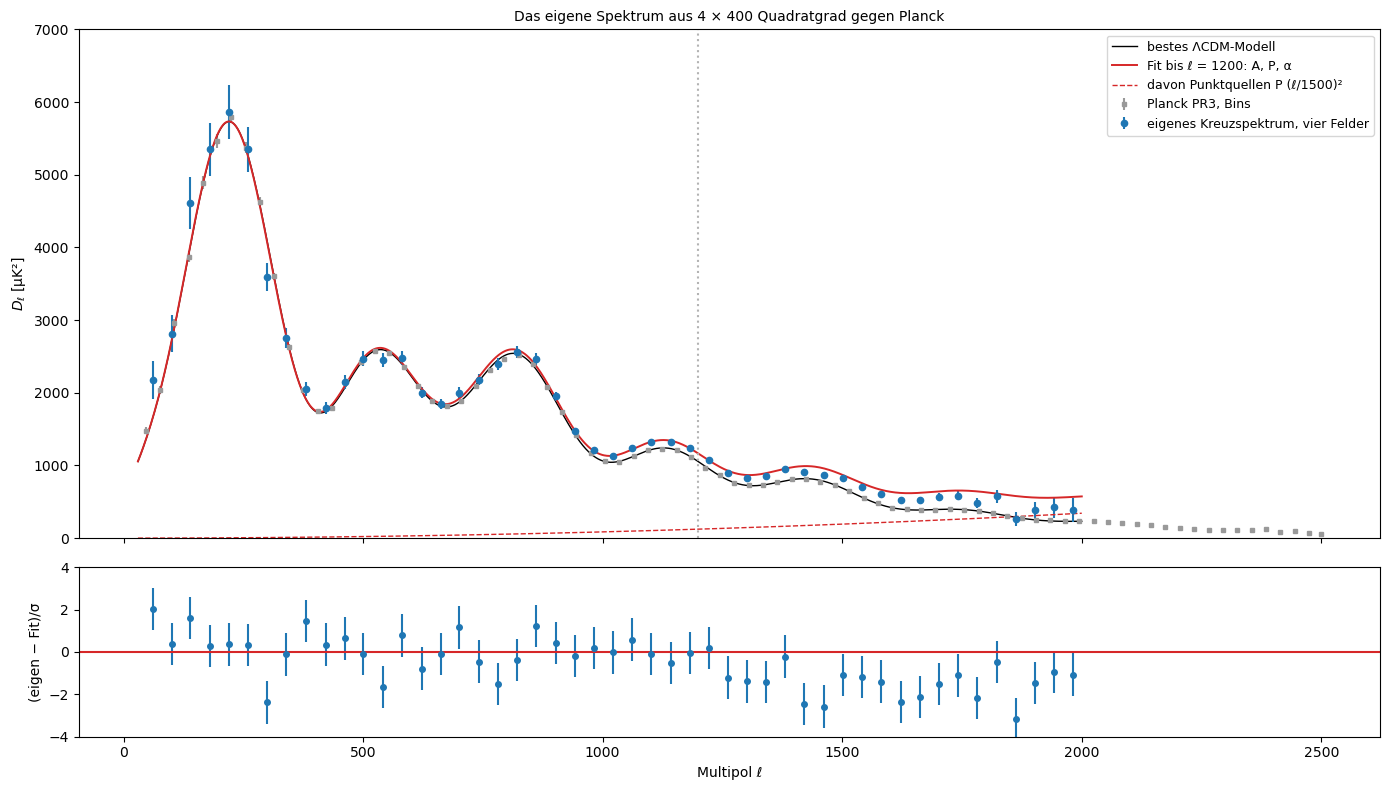

Fit bis ℓ = 1200: A = 1.000 ± 0.012, P = 193 ± 42 μK², α = 1.0022 ± 0.0027; χ² = 25.7 bei 26 Freiheitsgraden
eigenes 100 θ* = 1.0434 ± 0.0029 (Planck 1.04110)
  α = 1 fest        : A = 0.998, P =  188, α = 1.0000 ± 0.0000, χ² = 26.4 bei 27
  ohne Punktquellen : A = 1.038, P =    0, α = 1.0007 ± 0.0026, χ² = 46.4 bei 27
  bis ℓ = 2000      : A = 1.014, P =  123, α = 1.0012 ± 0.0022, χ² = 40.8 bei 46


In [8]:
names = list(MAPS)
lb, cross = field_mean(CLEAN, "100", "143")
_, auto100 = field_mean(CLEAN, "100", "100")
_, auto143 = field_mean(CLEAN, "143", "143")
w2, w4 = np.mean(WINDOW**2), np.mean(WINDOW**4)
n_ring = lb / ARC_STRETCH * np.diff(EDGES) * np.radians(SIZE) ** 2 / (2 * np.pi) * w2**2 / w4
sig = np.sqrt((auto100 * auto143 + cross**2) / (len(names) * n_ring))
LMAX_OWN = 1200


def own_model(p, ell=lb):
    A, P, alpha = p
    return A * d_theory(ell * alpha) + P * (ell / 1500) ** 2


def fit_own(lmax, free=(True, True, True)):
    # least squares bis lmax; nicht freie Größen bleiben bei A = 1, P = 0, α = 1
    m = lb <= lmax
    idx = [i for i in range(3) if free[i]]

    def full(q):
        p = np.array([1.0, 0.0, 1.0])
        p[idx] = q
        return p

    r = optimize.least_squares(lambda q: ((cross - own_model(full(q))) / sig)[m], np.array([1.0, 100.0, 1.0])[idx])
    e = np.zeros(3)
    e[idx] = np.sqrt(np.diag(np.linalg.inv(r.jac.T @ r.jac)))
    return full(r.x), e, np.sum(r.fun**2), m.sum() - len(idx)


p_own, e_own, chi2_own, dof_own = fit_own(LMAX_OWN)
theta_own = PLANCK["theta"][0] * p_own[2], PLANCK["theta"][0] * e_own[2]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ells = np.arange(30, 2001)
ax.errorbar(BINNED[:, 0], BINNED[:, 1], yerr=BINNED[:, 2], fmt="s", ms=3, color="0.6", label="Planck PR3, Bins")
ax.plot(ells, d_theory(ells), color="k", lw=1, label="bestes ΛCDM-Modell")
ax.errorbar(lb, cross, yerr=sig, fmt="o", ms=4.5, color="C0", label="eigenes Kreuzspektrum, vier Felder")
ax.plot(ells, own_model(p_own, ells), color="C3", lw=1.4, label=f"Fit bis ℓ = {LMAX_OWN}: A, P, α")
ax.plot(ells, p_own[1] * (ells / 1500) ** 2, color="C3", ls="--", lw=1, label="davon Punktquellen P (ℓ/1500)²")
ax.axvline(LMAX_OWN, color="0.7", ls=":")
ax.set_ylim(0, 7000)
ax.set_ylabel(r"$D_\ell$ [μK²]")
ax.set_title("Das eigene Spektrum aus 4 × 400 Quadratgrad gegen Planck", fontsize=10)
ax.legend(fontsize=9)
ax2.errorbar(lb, (cross - own_model(p_own)) / sig, yerr=1, fmt="o", ms=4, color="C0")
ax2.axhline(0, color="C3")
ax2.set_ylim(-4, 4)
ax2.set_xlabel("Multipol ℓ")
ax2.set_ylabel("(eigen − Fit)/σ")
plt.tight_layout()
plt.show()

print(f"Fit bis ℓ = {LMAX_OWN}: A = {p_own[0]:.3f} ± {e_own[0]:.3f}, P = {p_own[1]:.0f} ± {e_own[1]:.0f} μK², "
      f"α = {p_own[2]:.4f} ± {e_own[2]:.4f}; χ² = {chi2_own:.1f} bei {dof_own} Freiheitsgraden")
print(f"eigenes 100 θ* = {theta_own[0]:.4f} ± {theta_own[1]:.4f} (Planck {PLANCK['theta'][0]:.5f})")
for lmax, free, lab in [(LMAX_OWN, (True, True, False), "α = 1 fest"), (LMAX_OWN, (True, False, True), "ohne Punktquellen"),
                        (2000, (True, True, True), "bis ℓ = 2000")]:
    p, e, c2, dof = fit_own(lmax, free)
    print(f"  {lab:18s}: A = {p[0]:.3f}, P = {p[1]:4.0f}, α = {p[2]:.4f} ± {e[2]:.4f}, χ² = {c2:.1f} bei {dof}")

* Blau das eigene Kreuzspektrum aus vier Feldern ohne die Quellen, grau die Bins von Planck, schwarz das Modell, rot der Fit bis ℓ = 1200 und gestrichelt sein Anteil der Punktquellen. Die ersten drei Peaks sind deutlich zu sehen, der vierte und fünfte als Wellen über dem Anteil der Punktquellen. Unten die Abweichungen vom Fit: Bis ℓ = 1200 streuen sie um null; darüber liegt der Fit zu hoch, weil die einfache Form $P(\ell/1500)^2$ dort nicht mehr ganz passt.
* Der Fit gibt A = 1.000 ± 0.012, also dieselbe Kalibration wie Planck auf 1 %, dazu P = 193 ± 42 μK² und α = 1.0022 ± 0.0027 mit χ² = 25.7 bei 26 Freiheitsgraden. Daraus folgt 100 $\theta_\star$ = 1.0434 ± 0.0029 aus vier Feldern mit 3 % des Himmels, 0.8σ neben Planck. Ohne den Term für die Punktquellen steigt χ² auf 46.4. Mit α = 1 fest bleibt es bei 26.4: Die eigenen Felder brauchen keine Streckung gegenüber dem Modell.
* Zur Vorhersage: Drei Peaks sind deutlich, zwei weitere zeichnen sich ab. Bis ℓ = 2000 gibt der Fit α = 1.0012 ± 0.0022 (χ² = 40.8 bei 46), also ebenfalls das $\theta_\star$ von Planck.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-7"></a>

##### *7. Lage und Höhe der Peaks*

Wo genau liegen die Peaks und Täler im Spektrum von Planck, wie hoch sind sie, und wie genau lässt sich das bestimmen? Vorher vorhersagen: Ist der zweite Peak höher oder niedriger als der dritte, und was sagt das über die Baryonen (Theorie, Abschnitt 3)?

Der Code legt um jeden der ersten fünf Peaks und vier Täler ein gewichtetes kubisches Polynom durch das Spektrum der einzelnen ℓ und nimmt dessen Extremum. Den Fehler bestimmt er mit 300 Monte-Carlo-Wiederholungen: Jedes $D_\ell$ wird um seinen Fehler verrauscht und der Fit wiederholt. Dasselbe Verfahren auf das beste Modell angewandt gibt die Lagen, die das Modell vorhersagt. Am Ende rechnet er die Höhenverhältnisse $H_2 = D_{\ell_2}/D_{\ell_1}$ und $H_3 = D_{\ell_3}/D_{\ell_1}$.

**Hintergrund & Fachbegriffe:**
- **Monte-Carlo-Fehler:** Man wiederholt eine Auswertung mit künstlich verrauschten Daten; die Streuung der Ergebnisse ist ihr Fehler. Das geht auch, wenn die Auswertung zu verwickelt für eine Fehlerformel ist.
- **Kubisches Polynom:** Eine Parabel wäre um den Peak symmetrisch; die Peaks sind es nicht, weil das Spektrum zu großen ℓ hin abfällt. Das kubische Glied fängt die Schiefe auf.

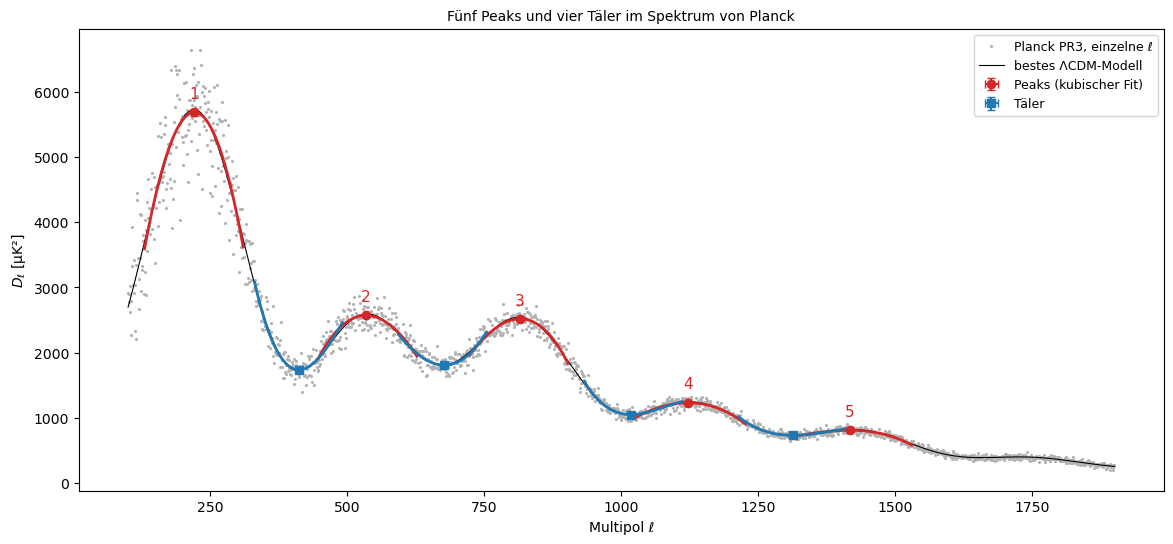

 Nr.   ℓ (Planck)      ℓ (Modell)   D (Planck) [μK²]   D (Modell)
Peak 1:   221.0 ±  3.3     219.6       5691 ±  55       5677
Peak 2:   534.0 ±  3.3     536.3       2571 ±  18       2567
Peak 3:   815.3 ±  2.8     812.7       2519 ±  14       2525
Peak 4:  1122.1 ±  3.1    1126.2       1230 ±   6       1229
Peak 5:  1416.7 ±  3.5    1421.1        807 ±   4        810
Tal  1:   411.8 ±  2.0     411.4       1736 ±  16       1735
Tal  2:   677.2 ±  3.0     673.5       1807 ±  12       1815
Tal  3:  1017.5 ±  2.1    1018.3       1049 ±   6       1049
Tal  4:  1313.7 ±  3.1    1314.9        729 ±   4        726
H2 = 0.4518 ± 0.0055 (Modell 0.4521),  H3 = 0.4425 ± 0.0051 (Modell 0.4447)


In [9]:
rng = np.random.default_rng(7)
N_MC = 300


def extrema(y):
    pk = np.array([fit_extremum(g, h, y, ERR, 1)[:2] for g, h in PEAKS])
    tr = np.array([fit_extremum(g, h, y, ERR, -1)[:2] for g, h in TROUGHS])
    return pk, tr


PK, TR = extrema(DL)
PK_T, TR_T = extrema(d_theory(L))
mc = [extrema(DL + rng.normal(0, ERR)) for _ in range(N_MC)]
PK_E = np.std([m[0] for m in mc], axis=0)
TR_E = np.std([m[1] for m in mc], axis=0)
H_OBS = np.array([PK[1, 1] / PK[0, 1], PK[2, 1] / PK[0, 1]])
H_MC = np.array([[m[0][1, 1] / m[0][0, 1], m[0][2, 1] / m[0][0, 1]] for m in mc])
H_THEORY = np.array([PK_T[1, 1] / PK_T[0, 1], PK_T[2, 1] / PK_T[0, 1]])

fig, ax = plt.subplots(figsize=(14, 6))
s = (L >= 100) & (L <= 1900)
ax.plot(L[s], DL[s], ".", ms=2.5, color="0.7", label="Planck PR3, einzelne ℓ")
ax.plot(L[s], d_theory(L[s]), color="k", lw=0.8, label="bestes ΛCDM-Modell")
for lst, sign, col in [(PEAKS, 1, "C3"), (TROUGHS, -1, "C0")]:
    for g, h in lst:
        x0, y0, c = fit_extremum(g, h, DL, ERR, sign)
        xs = np.linspace(-h, h, 200)
        ax.plot(g + xs, np.vander(xs, 4, increasing=True) @ c, color=col, lw=2)
ax.errorbar(PK[:, 0], PK[:, 1], xerr=PK_E[:, 0], yerr=PK_E[:, 1], fmt="o", color="C3", ms=6, capsize=3, label="Peaks (kubischer Fit)")
ax.errorbar(TR[:, 0], TR[:, 1], xerr=TR_E[:, 0], yerr=TR_E[:, 1], fmt="s", color="C0", ms=6, capsize=3, label="Täler")
for i, (x, y) in enumerate(PK):
    ax.annotate(f"{i + 1}", (x, y), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=11, color="C3")
ax.set_xlabel("Multipol ℓ")
ax.set_ylabel(r"$D_\ell$ [μK²]")
ax.set_title("Fünf Peaks und vier Täler im Spektrum von Planck", fontsize=10)
ax.legend(fontsize=9)
plt.show()

print(" Nr.   ℓ (Planck)      ℓ (Modell)   D (Planck) [μK²]   D (Modell)")
for i in range(len(PK)):
    print(f"Peak {i + 1}: {PK[i, 0]:7.1f} ± {PK_E[i, 0]:4.1f}   {PK_T[i, 0]:7.1f}     {PK[i, 1]:6.0f} ± {PK_E[i, 1]:3.0f}     {PK_T[i, 1]:6.0f}")
for i in range(len(TR)):
    print(f"Tal  {i + 1}: {TR[i, 0]:7.1f} ± {TR_E[i, 0]:4.1f}   {TR_T[i, 0]:7.1f}     {TR[i, 1]:6.0f} ± {TR_E[i, 1]:3.0f}     {TR_T[i, 1]:6.0f}")
print(f"H2 = {H_OBS[0]:.4f} ± {H_MC[:, 0].std():.4f} (Modell {H_THEORY[0]:.4f}),  H3 = {H_OBS[1]:.4f} ± {H_MC[:, 1].std():.4f} (Modell {H_THEORY[1]:.4f})")

* Grau das Spektrum für jedes ℓ, schwarz das Modell, farbig die kubischen Fits um die Peaks (rot) und Täler (blau) mit ihren Extrema. Der sechste Peak bei ℓ ≈ 1720 ist im Bild zu erkennen, liegt aber im steil fallenden Dämpfungsschwanz. Seine Lage ließe sich nur auf etwa ±35 bestimmen, deshalb bleibt er draußen.
* Die Peaks liegen bei ℓ = 221.0, 534.0, 815.3, 1122.1 und 1416.7, die Täler bei 411.8, 677.2, 1017.5 und 1313.7, alle auf ±2 bis ±3.5 genau. Die Lagen des Modells weichen um höchstens 4.4 ab (Peak 5: 1421.1), weniger als 1.5σ. Auch die Höhen stimmen: 5691, 2571, 2519, 1230 und 807 μK² gegen 5677, 2567, 2525, 1229 und 810 im Modell.
* Zur Vorhersage: Der zweite Peak (2571 μK²) ist kaum höher als der dritte (2519), obwohl das Spektrum insgesamt nach rechts abfällt. Der zweite Peak ist eine Verdünnung und wird von den Baryonen gedrückt, der dritte eine Verdichtung und wird angehoben (Theorie, Abschnitt 3). Mit H₂ = 0.4518 ± 0.0055 und H₃ = 0.4425 ± 0.0051 bestimmt Schritt 11 die Dichten.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-8"></a>

##### *8. Der Abstand der Peaks*

Welchen Winkel spannt der Schallhorizont am Himmel auf, wenn man nur die Lage der Peaks benutzt? Vorher vorhersagen: Wenn die Peaks im Mittel etwa 300 auseinanderliegen, wie groß ist $\theta_\star$ dann in Grad?

Nach Theorie, Abschnitt 3, liegen die Peaks bei $\ell_n \approx \ell_A (n - \varphi)$. Der Code passt diese Gerade an die fünf Peaks an, einmal für Planck und einmal für das beste Modell. Daraus folgt der Winkel auf zwei Arten:
- **roh:** $\theta_\star = \pi/\ell_A$,
- **geeicht:** Das beste Modell hat ein bekanntes $\theta_\star$ (100 $\theta_\star$ = 1.04110). Die Gerade macht bei Planck und beim Modell denselben Fehler, deshalb nimmt der Code nur das Verhältnis: $\theta_\star^\text{Planck} = \theta_\star^\text{Modell}\cdot \ell_A^\text{Modell}/\ell_A^\text{Planck}$.

Rechts stehen die Abweichungen von der Geraden. Den Fehler bestimmt der Code aus den Monte-Carlo-Wiederholungen von Schritt 7.

**Hintergrund & Fachbegriffe:**
- **Akustische Skala ℓ_A:** der Abstand benachbarter Peaks im Idealfall, π/$\theta_\star$.
- **Phasenverschiebung φ:** Die Peaks liegen etwas vor den Vielfachen von ℓ_A, weil die zerfallenden Potentiale die Schwingungen antreiben und die Sichtbarkeit der letzten Streufläche eine Breite hat.
- **Eichen an einer Simulation:** Ein einfaches Verfahren mit bekanntem systematischem Fehler wird an einem Modell gemessen, bei dem man die Antwort kennt, und der Fehler herausgerechnet. Das setzt voraus, dass der Fehler bei Daten und Modell gleich ist.

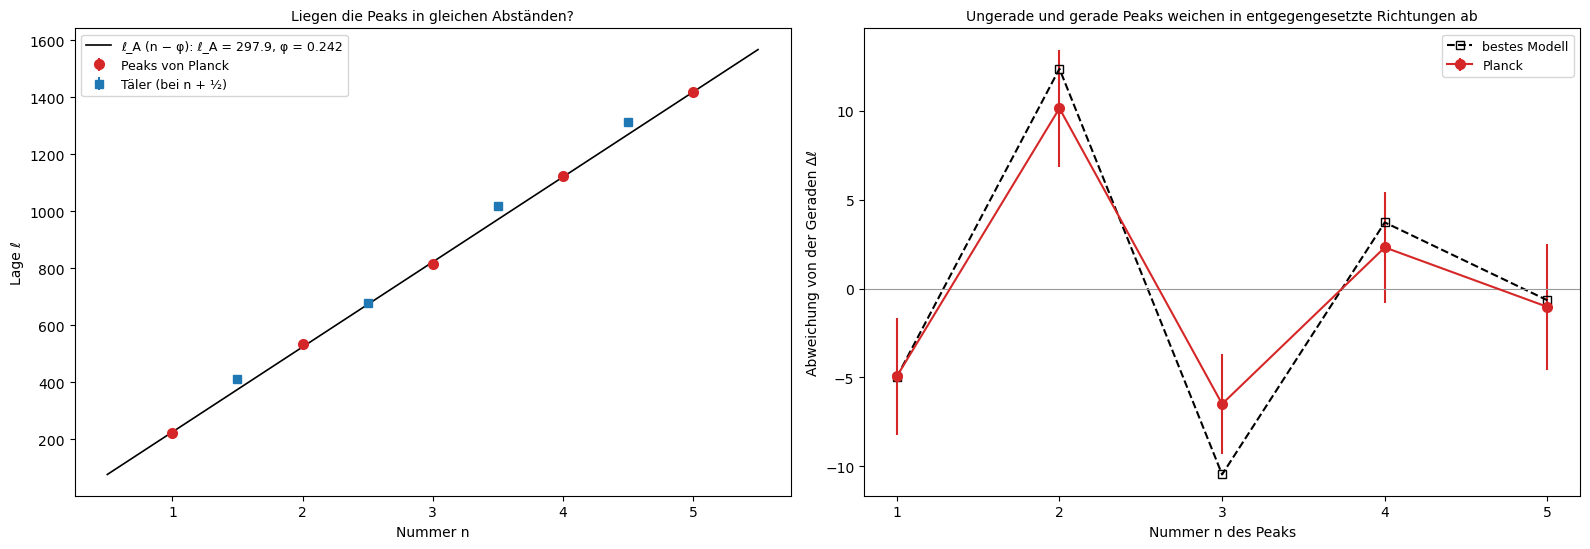

Planck: ℓ_A = 297.95 ± 1.08, φ = 0.242;  bestes Modell: ℓ_A = 299.28, φ = 0.249;  Hu et al.: φ ≈ 0.269
100 θ* roh π/ℓ_A = 1.0544 (das sind 0.604°); geeicht = 1.0458 ± 0.0038 (Planck 1.04110)
für das beste Modell gibt π/ℓ_A 100 θ* = 1.0497 statt 1.04110: Fehler der Geraden +0.83 %


In [10]:
n = np.arange(1, len(PK) + 1)
G = np.column_stack([n, -np.ones(len(n))])                  # ℓ_n = ℓ_A n − ℓ_A φ


def spacing(lp):
    c = np.linalg.lstsq(G, lp, rcond=None)[0]
    return c[0], c[1] / c[0]


LA, PHI = spacing(PK[:, 0])
LA_T, PHI_T = spacing(PK_T[:, 0])
la_mc = np.array([spacing(m[0][:, 0])[0] for m in mc])
THETA_RAW = 100 * np.pi / LA
THETA_PEAKS = (PLANCK["theta"][0] * LA_T / LA, PLANCK["theta"][0] * LA_T * la_mc.std() / LA**2)
r_hu = 0.042 / PLANCK["wm"][0] * PLANCK["zstar"][0] / 1000      # r* aus Hu et al. 2001, Gl. A5
phi_hu = 0.267 * (r_hu / 0.3) ** 0.1                              # Gl. A7

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.errorbar(n, PK[:, 0], yerr=PK_E[:, 0], fmt="o", color="C3", ms=7, label="Peaks von Planck")
ax.errorbar(np.arange(len(TR)) + 1.5, TR[:, 0], yerr=TR_E[:, 0], fmt="s", color="C0", ms=6, label="Täler (bei n + ½)")
nn = np.linspace(0.5, 5.5, 50)
ax.plot(nn, LA * (nn - PHI), color="k", lw=1.2, label=f"ℓ_A (n − φ): ℓ_A = {LA:.1f}, φ = {PHI:.3f}")
ax.set_xticks(n)
ax.set_xlabel("Nummer n")
ax.set_ylabel("Lage ℓ")
ax.set_title("Liegen die Peaks in gleichen Abständen?", fontsize=10)
ax.legend(fontsize=9)
ax2.errorbar(n, PK[:, 0] - LA * (n - PHI), yerr=PK_E[:, 0], fmt="o-", color="C3", ms=7, label="Planck")
ax2.plot(n, PK_T[:, 0] - LA_T * (n - PHI_T), "s--", color="k", ms=6, mfc="none", label="bestes Modell")
ax2.axhline(0, color="0.6", lw=0.8)
ax2.set_xticks(n)
ax2.set_xlabel("Nummer n des Peaks")
ax2.set_ylabel("Abweichung von der Geraden Δℓ")
ax2.set_title("Ungerade und gerade Peaks weichen in entgegengesetzte Richtungen ab", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"Planck: ℓ_A = {LA:.2f} ± {la_mc.std():.2f}, φ = {PHI:.3f};  bestes Modell: ℓ_A = {LA_T:.2f}, φ = {PHI_T:.3f};  "
      f"Hu et al.: φ ≈ {phi_hu:.3f}")
print(f"100 θ* roh π/ℓ_A = {THETA_RAW:.4f} (das sind {np.degrees(np.pi / LA):.3f}°); "
      f"geeicht = {THETA_PEAKS[0]:.4f} ± {THETA_PEAKS[1]:.4f} (Planck {PLANCK['theta'][0]:.5f})")
print(f"für das beste Modell gibt π/ℓ_A 100 θ* = {100 * np.pi / LA_T:.4f} statt 1.04110: Fehler der Geraden {100 * (np.pi / LA_T / 1.0411e-2 - 1):+.2f} %")

* Links die Lagen der Peaks (rot) und der Täler (blau, bei n + ½) gegen ihre Nummer, mit der Geraden ℓ_A (n − φ): ℓ_A = 297.95 ± 1.08 und φ = 0.242. Die Peaks liegen fast in gleichen Abständen. Die Täler liegen nicht genau in der Mitte zwischen zwei Peaks, meist 35 bis 50 dahinter, weil die Peaks schief sind.
* Rechts die Abweichungen von der Geraden. Planck und das Modell zeigen dasselbe Zickzack: Der zweite und vierte Peak liegen über der Geraden, der erste, dritte und fünfte darunter. Die Gerade ist also nur eine Näherung; am Modell macht sie $\theta_\star$ um 0.83 % zu groß. Roh gibt π/ℓ_A deshalb 100 $\theta_\star$ = 1.0544, 1.3 % über Planck. Geeicht am Modell bleibt 1.0458 ± 0.0038, 1.2σ über Planck.
* Zur Vorhersage: π/300 = 0.0105 rad = 0.60°. Unter diesem Winkel erscheint der Schallhorizont am Himmel, etwas größer als ein Vollmond. Das von Hu et al. vorhergesagte φ ≈ 0.27 passt ungefähr zu den gemessenen 0.24.

[↑ Zurück zur Landkarte](#landkarte)

#### **Modell und Fit**

<a id="exp-9"></a>

##### *9. Der Schallhorizont*

Wie weit kam eine Schallwelle bis zur Rekombination, und in welcher Epoche legte sie den größten Teil dieser Strecke zurück? Vorher vorhersagen: Wäre der Schallhorizont größer oder kleiner, wenn es keine Baryonen gäbe?

Der Code rechnet mit den Dichten von Planck (ω_b = 0.02237, ω_m = 0.1430, h = 0.6736). Links zeichnet er, wie sich das Verhältnis R von Baryonen zu Photonen und die Schallgeschwindigkeit $c_s$ mit der Rotverschiebung ändern. Rechts summiert er den Schallhorizont von $z = \infty$ herunter bis $z$ auf; bei $z_\star$ ist es $r_s$ (Theorie, Abschnitt 4). Er gibt $z_\star$, $r_s$, $D_M$ und $\theta_\star$ aus, dazu dieselbe Rechnung mit dem $z_\star$ von Planck statt der Näherung und ohne Baryonen in $c_s$.

**Hintergrund & Fachbegriffe:**
- **Gleichheit von Materie und Strahlung:** Bei $z_\text{eq} = \omega_m/\omega_r - 1 \approx 3400$ waren Materie und Strahlung gleich dicht. Davor dehnte sich das Universum wie $a \propto t^{1/2}$ aus, danach wie $t^{2/3}$.
- **Mitbewegte Strecke:** Alle Längen hier sind auf heute hochgerechnet; die echte Strecke damals war um den Faktor $1 + z_\star \approx 1090$ kleiner, etwa 130 000 Lichtjahre.

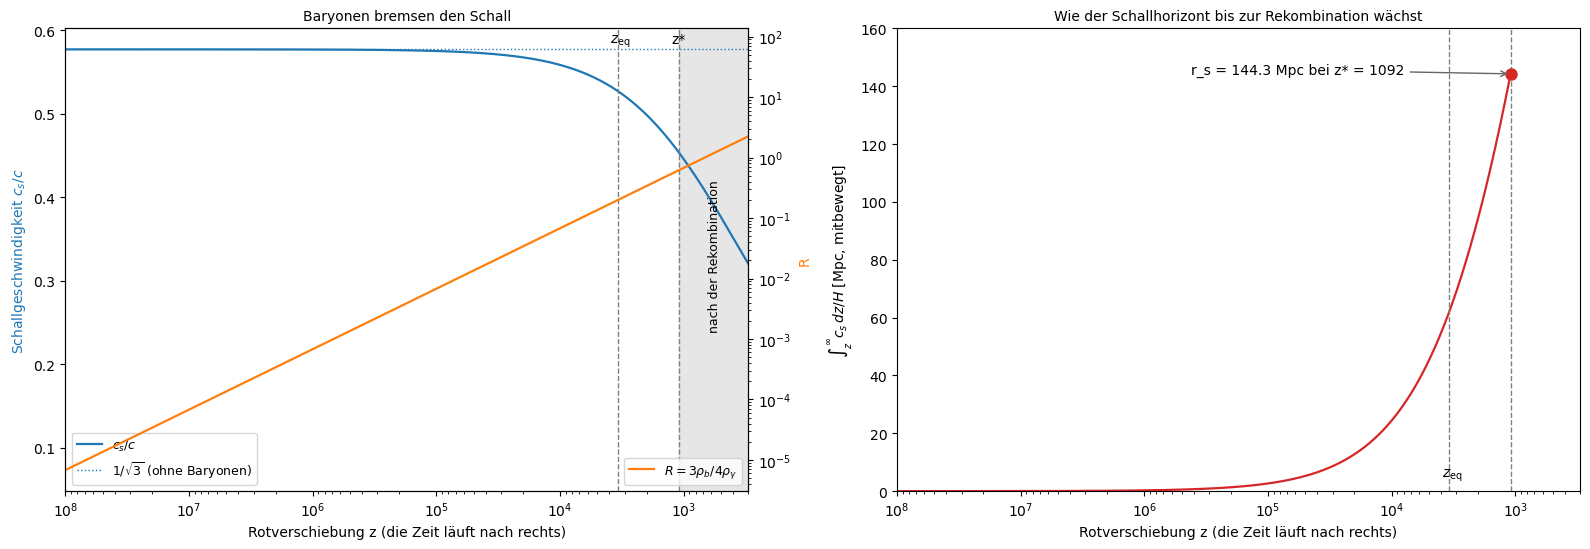

z* = 1091.91 (Näherung) gegen 1089.92 (Planck); z_eq = 3417; bei z*: R = 0.622, c_s = 0.453 c
r_s = 144.26 Mpc (Planck 144.43 ± 0.26), D_M = 13873 Mpc, 100 θ* = 1.03983 (Planck 1.0411)
mit z* von Planck: r_s = 144.43 Mpc, 100 θ* = 1.04110
ohne Baryonen in c_s: r_s = 161.7 Mpc (+12 %); vor z_eq entstanden 43 % von r_s


In [11]:
h0, wb0, wm0 = PLANCK["H0"][0] / 100, PLANCK["wb"][0], PLANCK["wm"][0]
cm0 = model(h0, wb0, wm0)
z = np.logspace(1, 8, 4000)
R = 3 * wb0 / (4 * OMEGA_G) / (1 + z)
cs = 1 / np.sqrt(3 * (1 + R))
dr = C_KMS * cs / cm0.H(z).value                                  # dr_s/dz [Mpc]
rs_above = np.concatenate([np.cumsum(((dr[1:] + dr[:-1]) / 2 * np.diff(z))[::-1])[::-1], [0.0]])   # ∫_z^∞
REF = acoustic(h0, wb0, wm0)
ref_pz = acoustic(h0, wb0, wm0, zs=PLANCK["zstar"][0])
cm_nob = lambda zz: C_KMS / np.sqrt(3) / cm0.H(zz).value
rs_nob = integrate.quad(cm_nob, REF["zs"], np.inf, limit=200)[0]
z_eq = wm0 / (OMEGA_G * (1 + 0.2271 * 3.046)) - 1                   # Strahlung: Photonen und 3.046 Neutrinoarten

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.6))
ax.plot(z, cs, color="C0", lw=1.6, label=r"$c_s/c$")
ax.axhline(1 / np.sqrt(3), color="C0", ls=":", lw=1, label=r"$1/\sqrt{3}$ (ohne Baryonen)")
ax.set_xscale("log")
ax.set_xlim(z[-1], 3e2)
ax.axvspan(3e2, REF["zs"], color="0.9", zorder=0)
ax.text(560, 0.33, "nach der Rekombination", rotation=90, fontsize=9, ha="center", va="center")
ax.set_xlabel("Rotverschiebung z (die Zeit läuft nach rechts)")
ax.set_ylabel(r"Schallgeschwindigkeit $c_s/c$", color="C0")
axr = ax.twinx()
axr.plot(z, R, color="C1", lw=1.6, label=r"$R = 3\rho_b/4\rho_\gamma$")
axr.set_yscale("log")
axr.set_ylabel("R", color="C1")
for zz, lab in [(REF["zs"], "z*"), (z_eq, r"$z_\mathrm{eq}$")]:
    ax.axvline(zz, color="0.5", ls="--", lw=1)
    ax.text(zz * 1.15, 0.585, lab, fontsize=10)
ax.set_title("Baryonen bremsen den Schall", fontsize=10)
ax.legend(loc="lower left", fontsize=9)
axr.legend(loc="lower right", fontsize=9)
before = z >= REF["zs"]
ax2.plot(z[before], rs_above[before], color="C3", lw=1.6)
ax2.axvline(REF["zs"], color="0.5", ls="--", lw=1)
ax2.axvline(z_eq, color="0.5", ls="--", lw=1)
ax2.plot(REF["zs"], REF["rs"], "o", color="C3", ms=8)
ax2.annotate(f"r_s = {REF['rs']:.1f} Mpc bei z* = {REF['zs']:.0f}", (REF["zs"], REF["rs"]), xytext=(-230, 0),
             textcoords="offset points", fontsize=10, arrowprops=dict(arrowstyle="->", color="0.4"))
ax2.text(z_eq * 1.15, 5, r"$z_\mathrm{eq}$", fontsize=10)
ax2.set_xscale("log")
ax2.set_xlim(z[-1], 3e2)
ax2.set_ylim(0, 160)
ax2.set_xlabel("Rotverschiebung z (die Zeit läuft nach rechts)")
ax2.set_ylabel(r"$\int_z^\infty c_s\,dz/H$ [Mpc, mitbewegt]")
ax2.set_title("Wie der Schallhorizont bis zur Rekombination wächst", fontsize=10)
plt.tight_layout()
plt.show()

k = np.argmin(np.abs(z - REF["zs"]))
print(f"z* = {REF['zs']:.2f} (Näherung) gegen {PLANCK['zstar'][0]} (Planck); z_eq = {z_eq:.0f}; "
      f"bei z*: R = {R[k]:.3f}, c_s = {cs[k]:.3f} c")
print(f"r_s = {REF['rs']:.2f} Mpc (Planck {PLANCK['rstar'][0]} ± {PLANCK['rstar'][1]}), D_M = {REF['dm']:.0f} Mpc, "
      f"100 θ* = {REF['theta']:.5f} (Planck {PLANCK['theta'][0]})")
print(f"mit z* von Planck: r_s = {ref_pz['rs']:.2f} Mpc, 100 θ* = {ref_pz['theta']:.5f}")
print(f"ohne Baryonen in c_s: r_s = {rs_nob:.1f} Mpc ({100 * (rs_nob / REF['rs'] - 1):+.0f} %); "
      f"vor z_eq entstanden {100 * np.interp(z_eq, z, rs_above) / REF['rs']:.0f} % von r_s")

* Links die Schallgeschwindigkeit (blau) und das Verhältnis R von Baryonen zu Photonen (orange); die Zeit läuft nach rechts. Ganz früh ist R winzig und $c_s = c/\sqrt3 = 0.577\,c$. Die Dichte der Photonen fällt wie (1+z)⁴, die der Baryonen nur wie (1+z)³, deshalb wächst R wie 1/(1+z). Bei $z_\star$ = 1092 ist R = 0.622 und c_s = 0.453 c. Grau ist die Zeit nach der Rekombination, in der es keinen Schall mehr gibt.
* Rechts der Schallhorizont, aufsummiert von z = ∞ an. Er wächst bis $z_\star$ auf r_s = 144.26 Mpc (mitbewegt); 43 % davon entstehen vor der Gleichheit von Materie und Strahlung bei z_eq = 3417. Mit den Dichten von Planck folgt D_M = 13 873 Mpc und 100 $\theta_\star$ = 1.03983, 0.12 % unter Planck. Mit dem $z_\star$ von Planck (1089.92) statt der Näherung (1091.91) kommen genau r_s = 144.43 Mpc und 100 $\theta_\star$ = 1.04110 heraus wie bei Planck. Der kleine Unterschied kommt also nur von der Näherung für $z_\star$.
* Zur Vorhersage: Ohne Baryonen wäre der Schall schneller und r_s mit 161.7 Mpc um 12 % größer.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-10"></a>

##### *10. Die Schablone: $\theta_\star$ aus dem ganzen Spektrum*

Wie genau lässt sich $\theta_\star$ bestimmen, wenn man nicht nur die Peaks, sondern die Form des ganzen Spektrums benutzt? Vorher vorhersagen: Wird der Fehler kleiner, wenn man das Spektrum bis ℓ = 2500 statt bis 800 nimmt, obwohl die Fehler bei großen ℓ wachsen?

Ändert sich $\theta_\star$, rücken alle akustischen Strukturen entlang ℓ im selben Verhältnis. Der Code streckt deshalb das beste Modell, $D_\ell \to A\,D^\text{Modell}_{\alpha\ell}$, und sucht das α mit dem kleinsten χ² gegen die einzelnen ℓ von Planck ab ℓ = 30. Die Amplitude A rechnet er für jedes α in geschlossener Form aus. Dann ist $\theta_\star = \alpha \cdot \theta_\star^\text{Modell}$; den Fehler gibt die Stelle mit Δχ² = 1. Er macht das bis ℓ = 800, 1500 und 2508.

**Hintergrund & Fachbegriffe:**
- **Profil-χ²:** χ² als Funktion eines Parameters, minimiert über alle anderen; Δχ² = 1 über dem Minimum markiert die 1σ-Grenzen.
- **Annahme der Schablone:** Nur die Lage aller Strukturen ändert sich, nicht ihre Form. Das stimmt für die akustischen Peaks gut. Die Dämpfung bei großen ℓ hängt aber auch von anderen Größen ab; Planck fittet deshalb alle Parameter zugleich.

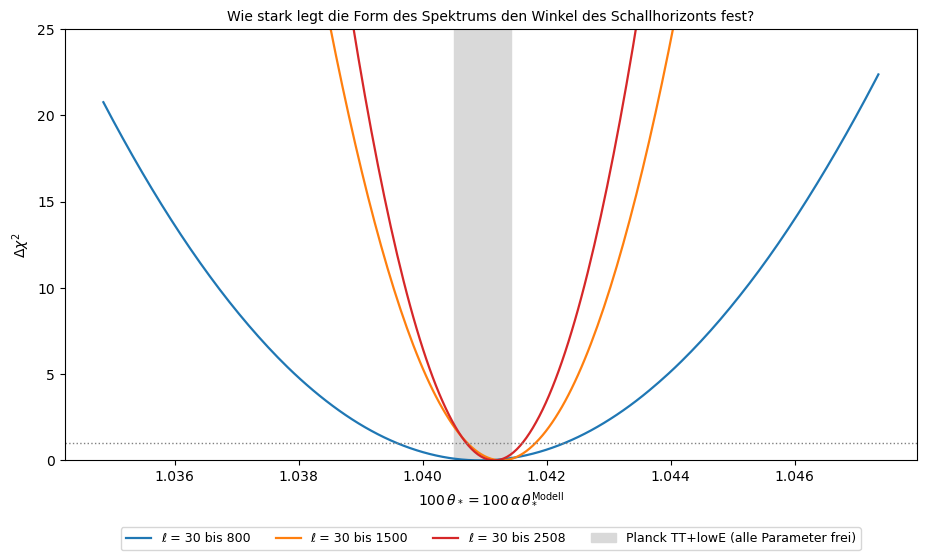

ℓ bis  800: α = 0.99984 ± 0.00130, 100 θ* = 1.04093 ± 0.00135, A = 0.9991, χ² = 845 bei 771 Werten
ℓ bis 1500: α = 1.00016 ± 0.00053, 100 θ* = 1.04127 ± 0.00055, A = 0.9998, χ² = 1560 bei 1471 Werten
ℓ bis 2508: α = 1.00005 ± 0.00043, 100 θ* = 1.04116 ± 0.00045, A = 1.0000, χ² = 2550 bei 2479 Werten
Planck TT+lowE: 100 θ* = 1.04097 ± 0.00046; Abstand +0.3 σ


In [12]:
use = L >= 30


def chi2_stretch(alpha, lmax):
    s = use & (L <= lmax)
    t = d_theory(L[s] * alpha)
    A = np.sum(DL[s] * t / ERR[s] ** 2) / np.sum(t**2 / ERR[s] ** 2)
    return np.sum(((DL[s] - A * t) / ERR[s]) ** 2), A


alphas = np.linspace(0.994, 1.006, 241)
STRETCH = {}
fig, ax = plt.subplots(figsize=(11, 5.6))
for lmax, col in [(800, "C0"), (1500, "C1"), (2508, "C3")]:
    prof = np.array([chi2_stretch(a, lmax)[0] for a in alphas])
    k = np.argmin(prof)
    c = np.polyfit(alphas[max(k - 15, 0):k + 16] - alphas[k], prof[max(k - 15, 0):k + 16], 2)
    a_best = alphas[k] - c[1] / (2 * c[0])
    STRETCH[lmax] = (a_best, 1 / np.sqrt(c[0]), prof.min(), chi2_stretch(a_best, lmax)[1], np.sum(use & (L <= lmax)))
    ax.plot(PLANCK["theta"][0] * alphas, prof - prof.min(), color=col, lw=1.6, label=f"ℓ = 30 bis {lmax}")
ax.axhline(1, color="0.5", ls=":", lw=1)
ax.axvspan(PLANCK_TT["theta"][0] - PLANCK_TT["theta"][1], PLANCK_TT["theta"][0] + PLANCK_TT["theta"][1], color="0.85",
           label="Planck TT+lowE (alle Parameter frei)")
ax.set_ylim(0, 25)
ax.set_xlabel(r"$100\,\theta_* = 100\,\alpha\,\theta_*^\mathrm{Modell}$")
ax.set_ylabel(r"$\Delta\chi^2$")
ax.set_title("Wie stark legt die Form des Spektrums den Winkel des Schallhorizonts fest?", fontsize=10)
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
plt.show()

for lmax, (a, e, c2, A, nn) in STRETCH.items():
    print(f"ℓ bis {lmax:4d}: α = {a:.5f} ± {e:.5f}, 100 θ* = {PLANCK['theta'][0] * a:.5f} ± {PLANCK['theta'][0] * e:.5f}, "
          f"A = {A:.4f}, χ² = {c2:.0f} bei {nn} Werten")
THETA_FIT = (PLANCK["theta"][0] * STRETCH[2508][0], PLANCK["theta"][0] * STRETCH[2508][1])
print(f"Planck TT+lowE: 100 θ* = {PLANCK_TT['theta'][0]} ± {PLANCK_TT['theta'][1]}; "
      f"Abstand {(THETA_FIT[0] - PLANCK_TT['theta'][0]) / np.hypot(THETA_FIT[1], PLANCK_TT['theta'][1]):+.1f} σ")

* Δχ² als Funktion von $\theta_\star$ für drei Bereiche von ℓ, grau der Wert von Planck aus TT+lowE mit allen Parametern frei. Alle drei Kurven haben ihr Minimum zwischen 100 $\theta_\star$ = 1.0409 und 1.0413.
* Bis ℓ = 800 ist der Fehler ±0.00135, bis 1500 ±0.00055, bis 2508 ±0.00045. Das gibt 100 $\theta_\star$ = 1.04116 ± 0.00045, auf 0.04 % genau und 0.3σ neben Planck TT+lowE (1.04097 ± 0.00046); die Amplitude ist A = 1.0000. Ganz unabhängig von Planck ist das nicht: Die Schablone ist das beste Modell, der Fit prüft nur, ob das gemessene Spektrum gegen das Modell verschoben ist.
* Zur Vorhersage: Ja, der Fehler wird kleiner, zwischen ℓ = 1500 und 2508 aber kaum noch (0.00055 auf 0.00045), weil dort das Rauschen überwiegt (Schritt 5). Die meiste Information über $\theta_\star$ steckt in den Peaks 2 bis 5.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-11"></a>

##### *11. Baryonen und Materie aus den Peakhöhen*

Was verraten die Höhen der Peaks über die Dichten von Baryonen und Materie? Vorher vorhersagen: Welches der beiden Verhältnisse, H₂ oder H₃, hängt stärker von ω_b ab?

Der Code löst die beiden Formeln von Hu et al. (2001) aus Theorie, Abschnitt 3, nach $\omega_b$ und $\omega_m$ auf. Er setzt dafür die gemessenen $H_2$ und $H_3$ aus Schritt 7 und $n_s = 0.9649$ von Planck ein. Für jede der 300 Monte-Carlo-Wiederholungen löst er die Gleichungen erneut; das gibt den statistischen Fehler. Den Fehler der Formeln selbst misst er am besten Modell: Seine Peakhöhen kennt man aus Schritt 7, seine Dichten aus Planck. Im Bild stehen die Streifen, auf denen $H_2$ und $H_3$ den gemessenen Wert haben; wo sie sich kreuzen, liegen die Dichten.

**Hintergrund & Fachbegriffe:**
- **Näherungsformel (Fitting Formula):** eine einfache Funktion, die an viele genaue Rechnungen angepasst ist; schnell und durchschaubar, aber nur so genau, wie die Anpassung war (hier einige Prozent) und nur in dem Bereich, in dem angepasst wurde.
- **Entartung:** Zwei Parameter, deren Änderungen sich in einer Messgröße ausgleichen; ein Streifen im Bild ist eine Linie gleicher Peakhöhe. Erst zwei Streifen mit verschiedener Richtung legen beide fest.
- **Lensing der Hintergrundstrahlung:** Die Schwerkraft der Strukturen auf dem Weg zu uns lenkt das Licht leicht ab und verwischt die Peaks um etwa 1 %. Die Formeln von Hu et al. enthalten das nicht.

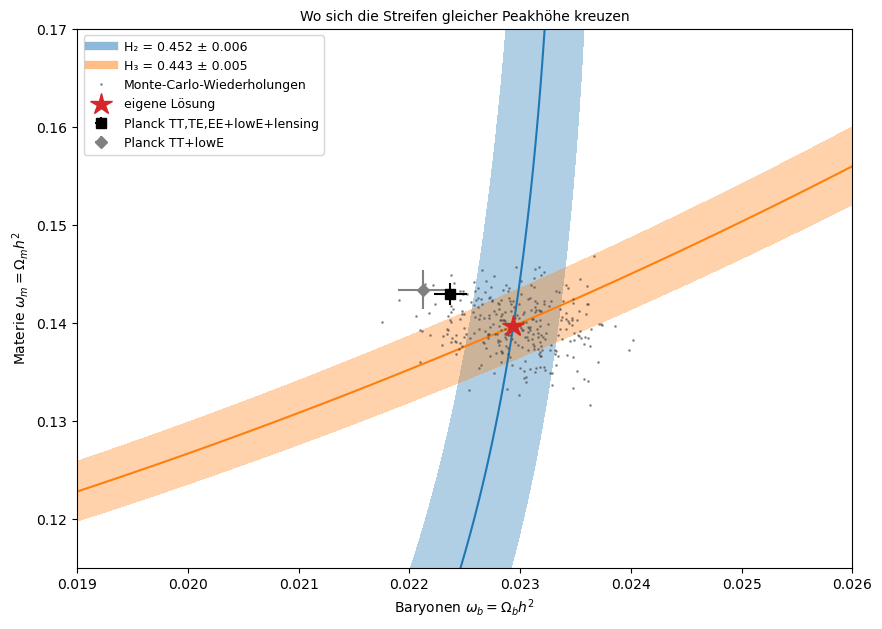

Formeln am besten Modell: H₂ um +1.8 %, H₃ um +1.5 % daneben
ω_b = 0.02294 ± 0.00039 (stat.) ± 0.00057 (Formel), Planck 0.02237
ω_m = 0.1397 ± 0.0027 (stat.) ± 0.0018 (Formel), Planck 0.143
mit n_s = 0.955: ω_b = 0.02269, ω_m = 0.1424
mit n_s = 0.975: ω_b = 0.02319, ω_m = 0.1370


In [13]:
NS = PLANCK["ns"][0]


def invert(h2, h3, ns=NS):
    return optimize.fsolve(lambda p: [h2_hu(*p, ns) - h2, h3_hu(*p, ns) - h3], [0.022, 0.14])


WB_OWN, WM_OWN = invert(*H_OBS)
W_MC = np.array([invert(*h) for h in H_MC])
formula_err = np.array([h2_hu(wb0, wm0, NS), h3_hu(wb0, wm0, NS)]) / H_THEORY - 1        # Fehler der Formeln am Modell
wb_cal, wm_cal = invert(*(H_OBS * (1 + formula_err)))
W_SYS = np.abs([WB_OWN - wb_cal, WM_OWN - wm_cal])

gb, gm = np.meshgrid(np.linspace(0.019, 0.026, 300), np.linspace(0.115, 0.170, 300))
fig, ax = plt.subplots(figsize=(10, 7))
for f, h, e, col, lab in [(h2_hu, H_OBS[0], H_MC[:, 0].std(), "C0", "H₂"), (h3_hu, H_OBS[1], H_MC[:, 1].std(), "C1", "H₃")]:
    v = f(gb, gm, NS)
    ax.contourf(gb, gm, np.abs(v - h), levels=[0, e], colors=[col], alpha=0.35)
    ax.contour(gb, gm, v, levels=[h], colors=[col], linewidths=1.5)
    ax.plot([], [], color=col, lw=6, alpha=0.5, label=f"{lab} = {h:.3f} ± {e:.3f}")
ax.plot(W_MC[:, 0], W_MC[:, 1], ".", ms=2, color="0.3", alpha=0.5, label="Monte-Carlo-Wiederholungen")
ax.plot(WB_OWN, WM_OWN, "*", ms=16, color="C3", label="eigene Lösung")
ax.errorbar(PLANCK["wb"][0], PLANCK["wm"][0], xerr=PLANCK["wb"][1], yerr=PLANCK["wm"][1], fmt="s", color="k", ms=7,
            label="Planck TT,TE,EE+lowE+lensing")
ax.errorbar(PLANCK_TT["wb"][0], PLANCK_TT["wm"][0], xerr=PLANCK_TT["wb"][1], yerr=PLANCK_TT["wm"][1], fmt="D", color="0.5",
            ms=6, label="Planck TT+lowE")
ax.set_xlabel(r"Baryonen $\omega_b = \Omega_b h^2$")
ax.set_ylabel(r"Materie $\omega_m = \Omega_m h^2$")
ax.set_title("Wo sich die Streifen gleicher Peakhöhe kreuzen", fontsize=10)
ax.legend(fontsize=9, loc="upper left")
plt.show()

print(f"Formeln am besten Modell: H₂ um {100 * formula_err[0]:+.1f} %, H₃ um {100 * formula_err[1]:+.1f} % daneben")
print(f"ω_b = {WB_OWN:.5f} ± {W_MC[:, 0].std():.5f} (stat.) ± {W_SYS[0]:.5f} (Formel), Planck {PLANCK['wb'][0]}")
print(f"ω_m = {WM_OWN:.4f} ± {W_MC[:, 1].std():.4f} (stat.) ± {W_SYS[1]:.4f} (Formel), Planck {PLANCK['wm'][0]}")
for ns in (0.955, 0.975):
    print(f"mit n_s = {ns}: ω_b = {invert(*H_OBS, ns)[0]:.5f}, ω_m = {invert(*H_OBS, ns)[1]:.4f}")

* Blau der Streifen, auf dem die Formel von Hu et al. das gemessene H₂ ± 1σ ergibt, orange der für H₃. H₂ hängt vor allem an ω_b (der Streifen steht fast senkrecht), H₃ an ω_m (der Streifen liegt flach). Sie kreuzen sich bei ω_b = 0.02294 und ω_m = 0.1397 (Stern); die Punkte sind die 300 Monte-Carlo-Wiederholungen.
* Mit Fehlern: ω_b = 0.02294 ± 0.00039 (stat.) ± 0.00057 (Formel) und ω_m = 0.1397 ± 0.0027 (stat.) ± 0.0018 (Formel). Planck (0.02237 und 0.1430) liegt 0.8σ und 1.0σ daneben. Die Formeln liegen am besten Modell um +1.8 % (H₂) und +1.5 % (H₃) daneben; Hu et al. geben Fehler von einigen Prozent an, und das Lensing fehlt in ihnen. Auch der Spektralindex zählt: Mit n_s = 0.955 statt 0.965 käme ω_m = 0.1424 heraus, mit 0.975 0.1370.
* Zur Vorhersage: H₂, das Verhältnis der ersten Verdünnung zur ersten Verdichtung, hängt am stärksten von ω_b ab.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-12"></a>

##### *12. H₀ aus dem Winkel des Schallhorizonts*

Welche Hubble-Konstante folgt aus $\theta_\star$, und wie hängt sie davon ab, woher man die Dichten nimmt? Vorher vorhersagen: Steigt oder fällt das H₀ aus $\theta_\star$, wenn ω_m kleiner ist?

Der Code sucht das $h$, für das $100\,\theta_\star(h)$ aus Theorie, Abschnitt 4, den Wert aus Schritt 10 trifft. Er tut das auf drei Arten, die sich darin unterscheiden, woher die Dichten kommen:
- **A, Prüfung der Rechenkette:** $\omega_b$ und $\omega_m$ von Planck.
- **B, ganz aus dem Spektrum:** $\omega_b$ und $\omega_m$ aus den eigenen Peakhöhen (Schritt 11). Der Fehler kommt aus 100 Monte-Carlo-Wiederholungen von Dichten und $\theta_\star$, dazu der Fehler der Formeln.
- **C, mit den Supernovae:** $\omega_b$ aus den Peakhöhen, aber statt $\omega_m$ der Anteil $\Omega_m = 0.333 \pm 0.018$ aus Pantheon+ (Theorie, Abschnitt 5).

Links steht $100\,\theta_\star$ als Funktion von $H_0$ für die Dichten von A und B, rechts die Linie, die $\theta_\star$ in der Ebene von $\Omega_m$ und $H_0$ festlegt, neben den Supernovae und SH0ES.

**Hintergrund & Fachbegriffe:**
- **Inverse Entfernungsleiter:** H₀ aus einem Maßstab des frühen Universums (hier $r_s$) und einer Entfernung, statt aus Cepheiden und Supernovae von nah nach fern.
- **Ω_m h³:** die Kombination, die $\theta_\star$ bei festem $\omega_b$ fast allein festlegt; Planck misst sie auf 0.3 %.

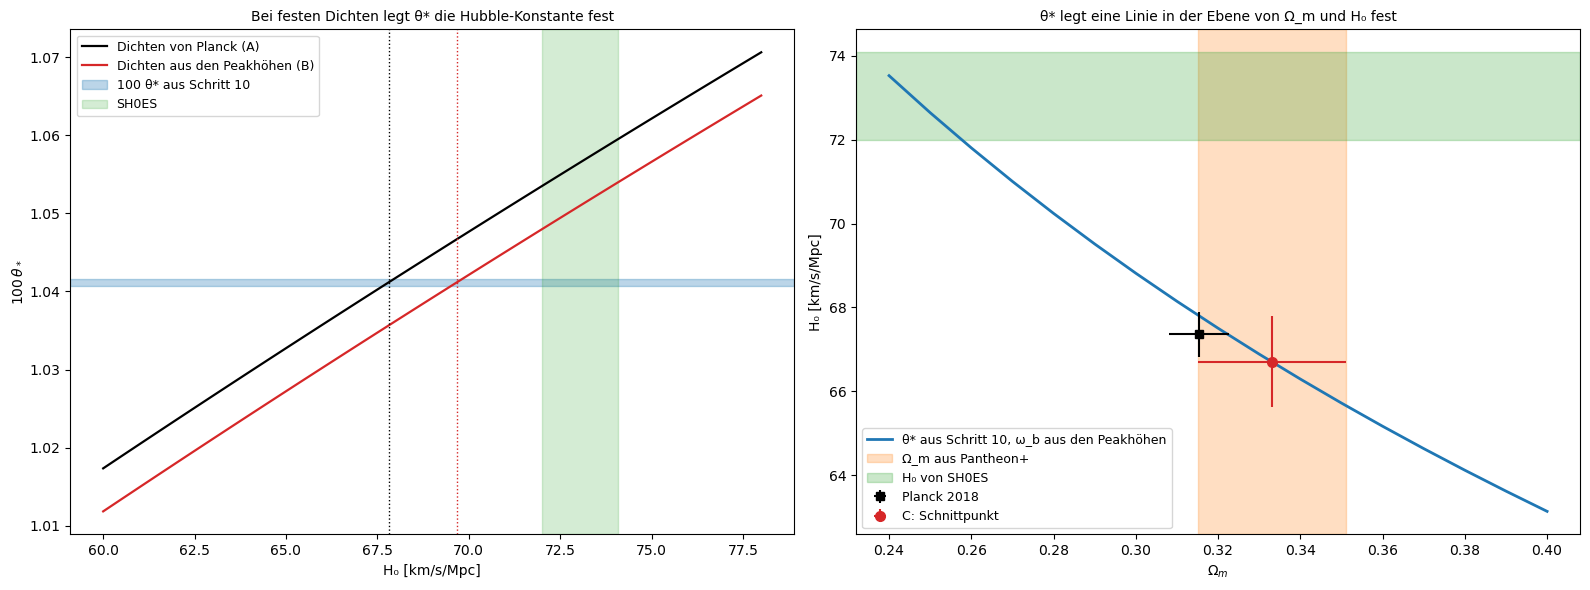

A (Dichten von Planck):       H₀ = 67.80 km/s/Mpc  (Planck selbst 67.36 ± 0.54)
B (Dichten aus Peakhöhen):    H₀ = 69.67 ± 1.03 (stat.) ± 1.32 (Formel)
C (ω_b, Ω_m aus Pantheon+):   H₀ = 66.71 ± 1.08
Ω_m h³ entlang der Linie: 0.0954 bis 0.1007 (Planck 0.0963)
mit dem z* von Planck statt der Näherung, Dichten von Planck: H₀ = 67.38


In [14]:
wb_mc, wm_mc = W_MC[:100, 0], W_MC[:100, 1]
th_mc = THETA_FIT[0] + rng.normal(0, THETA_FIT[1], 100)
H_A = 100 * h_from_theta(THETA_FIT[0], wb0, wm0)
H_B = 100 * h_from_theta(THETA_FIT[0], WB_OWN, WM_OWN)
hb_mc = np.array([100 * h_from_theta(t, b, m) for t, b, m in zip(th_mc, wb_mc, wm_mc)])
hb_sys = abs(100 * h_from_theta(THETA_FIT[0], wb_cal, wm_cal) - H_B)
H_B_ERR = np.hypot(hb_mc.std(), hb_sys)
H_C = 100 * h_from_theta(THETA_FIT[0], WB_OWN, Om=OM_SN[0])
hc_pm = [100 * h_from_theta(THETA_FIT[0], WB_OWN, Om=OM_SN[0] + d * OM_SN[1]) for d in (-1, 1)]
H_C_ERR = abs(hc_pm[0] - hc_pm[1]) / 2

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 6))
hh = np.linspace(0.60, 0.78, 37)
for (b, m, lab, col) in [(wb0, wm0, "Dichten von Planck (A)", "k"), (WB_OWN, WM_OWN, "Dichten aus den Peakhöhen (B)", "C3")]:
    ax.plot(100 * hh, [acoustic(x, b, m)["theta"] for x in hh], color=col, lw=1.6, label=lab)
ax.axhspan(THETA_FIT[0] - THETA_FIT[1], THETA_FIT[0] + THETA_FIT[1], color="C0", alpha=0.3, label="100 θ* aus Schritt 10")
ax.axvline(H_A, color="k", ls=":", lw=1)
ax.axvline(H_B, color="C3", ls=":", lw=1)
ax.axvspan(H0_SH0ES[0] - H0_SH0ES[1], H0_SH0ES[0] + H0_SH0ES[1], color="C2", alpha=0.2, label="SH0ES")
ax.set_xlabel("H₀ [km/s/Mpc]")
ax.set_ylabel(r"$100\,\theta_*$")
ax.set_title("Bei festen Dichten legt θ* die Hubble-Konstante fest", fontsize=10)
ax.legend(fontsize=9)
oms = np.linspace(0.24, 0.40, 17)
line = np.array([100 * h_from_theta(THETA_FIT[0], WB_OWN, Om=o) for o in oms])
ax2.plot(oms, line, color="C0", lw=2, label="θ* aus Schritt 10, ω_b aus den Peakhöhen")
ax2.axvspan(OM_SN[0] - OM_SN[1], OM_SN[0] + OM_SN[1], color="C1", alpha=0.25, label="Ω_m aus Pantheon+")
ax2.axhspan(H0_SH0ES[0] - H0_SH0ES[1], H0_SH0ES[0] + H0_SH0ES[1], color="C2", alpha=0.25, label="H₀ von SH0ES")
ax2.errorbar(PLANCK["Om"][0], PLANCK["H0"][0], xerr=PLANCK["Om"][1], yerr=PLANCK["H0"][1], fmt="s", color="k", label="Planck 2018")
ax2.errorbar(OM_SN[0], H_C, xerr=OM_SN[1], yerr=H_C_ERR, fmt="o", color="C3", ms=7, label="C: Schnittpunkt")
ax2.set_xlabel(r"$\Omega_m$")
ax2.set_ylabel("H₀ [km/s/Mpc]")
ax2.set_title("θ* legt eine Linie in der Ebene von Ω_m und H₀ fest", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"A (Dichten von Planck):       H₀ = {H_A:.2f} km/s/Mpc  (Planck selbst {PLANCK['H0'][0]} ± {PLANCK['H0'][1]})")
print(f"B (Dichten aus Peakhöhen):    H₀ = {H_B:.2f} ± {hb_mc.std():.2f} (stat.) ± {hb_sys:.2f} (Formel)")
print(f"C (ω_b, Ω_m aus Pantheon+):   H₀ = {H_C:.2f} ± {H_C_ERR:.2f}")
print(f"Ω_m h³ entlang der Linie: {np.min(oms * (line / 100) ** 3):.4f} bis {np.max(oms * (line / 100) ** 3):.4f} (Planck 0.0963)")
print(f"mit dem z* von Planck statt der Näherung, Dichten von Planck: H₀ = "
      f"{100 * optimize.brentq(lambda h: acoustic(h, wb0, wm0, zs=PLANCK['zstar'][0])['theta'] - THETA_FIT[0], 0.5, 0.9):.2f}")

* Links 100 $\theta_\star$ als Funktion von H₀. Mit den Dichten von Planck (schwarz) schneidet die Kurve das Band aus Schritt 10 bei H₀ = 67.80, mit den eigenen Dichten (rot) bei 69.67. Für H₀ = 73 bräuchte man bei den Dichten von Planck 100 $\theta_\star$ ≈ 1.056, 1.5 % mehr als gemessen.
* Die drei Wege: A gibt 67.80; Planck selbst hat 67.36, die 0.44 kommen aus der Näherung für $z_\star$ (mit dem $z_\star$ von Planck wären es 67.38). B gibt 69.67 ± 1.03 (stat.) ± 1.32 (Formel). Das liegt höher, weil die Formeln ein kleineres ω_m und ein größeres ω_b liefern, und beides hebt H₀. C gibt mit Ω_m = 0.333 aus Pantheon+ 66.71 ± 1.08.
* Rechts die Linie, die $\theta_\star$ in der Ebene von Ω_m und H₀ festlegt. Entlang der Linie ändert sich Ω_m h³ nur um ±3 % (0.0954 bis 0.1007), während Ω_m von 0.24 bis 0.40 läuft. Die Linie kreuzt das Band von Pantheon+ bei H₀ ≈ 66.7 und das Band von SH0ES erst bei Ω_m ≈ 0.24. Zur Vorhersage: Ein kleineres ω_m gibt ein größeres H₀.

[↑ Zurück zur Landkarte](#landkarte)

#### **Eigene Messung gegen den Katalog**

<a id="exp-13"></a>

##### *13. Gegen Planck 2018 und SH0ES*

Wie gut stimmen die eigenen Werte mit denen von Planck überein, und wie groß ist die Spannung zur Entfernungsleiter? Vorher vorhersagen: Welcher der eigenen Werte für H₀ liegt am nächsten an SH0ES?

Der Code stellt die eigenen Zahlen neben die von Planck 2018 (Tabelle 2): $\theta_\star$, $z_\star$, r_s, ω_b, ω_m und H₀. Dazu kommt ein vierter Wert D, der $\theta_\star$ aus den eigenen Karten von Schritt 6 mit den Dichten aus den Peakhöhen verbindet. Im Bild stehen alle Werte für H₀ untereinander, mit SH0ES und dem Wert aus [Das Hubble-Diagramm](https://github.com/deltorobarba/science/blob/main/astro/cosmology_hubblediagram.ipynb). Für jeden eigenen Wert gibt er den Abstand zu SH0ES in Standardabweichungen aus.

**Hintergrund & Fachbegriffe:**
- **Abstand in σ:** Unterschied zweier Werte geteilt durch die Wurzel aus der Summe ihrer Varianzen; ab etwa 3σ spricht man von einer Spannung, ab 5σ gilt sie als gesichert.
- **TT+lowE gegen TT,TE,EE+lowE+lensing:** Planck nur mit dem Temperaturspektrum und der Polarisation bei großen Winkeln, gegen alles zusammen; dieses Notebook benutzt nur Temperatur, der Vergleich mit TT+lowE ist deshalb der gerechtere.

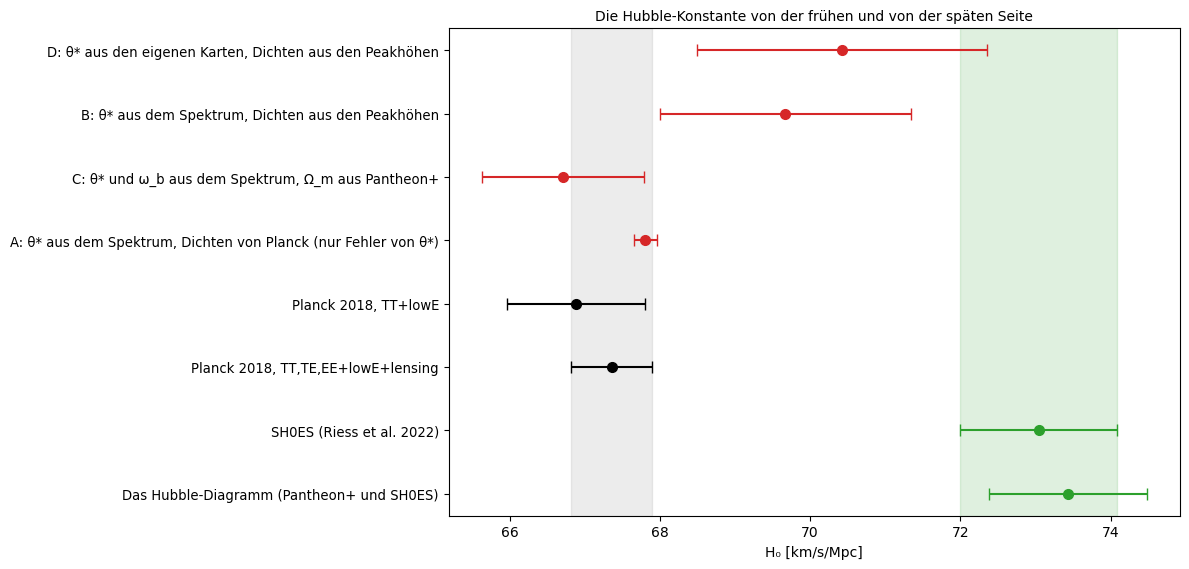

Größe         eigen                          Planck 2018 (TT,TE,EE+lowE+lensing)
100 θ*        1.04116 ± 0.00045 (Schablone)     1.0411 ± 0.00031  (TT+lowE 1.04097 ± 0.00046)
              1.0434 ± 0.0029 (eigene Karten)
              1.0458 ± 0.0038 (Abstand der Peaks)
z*            1091.9 (Näherung)                   1089.92 ± 0.25
r_s [Mpc]     144.26 (mit Planck-Dichten)        144.43 ± 0.26
ω_b           0.02294 ± 0.00069                0.02237 ± 0.00015
ω_m           0.1397 ± 0.0032                  0.143 ± 0.0011
D: H₀ = 70.43 ± 1.93: gegen SH0ES 1.2 σ, gegen Planck +1.5 σ
B: H₀ = 69.67 ± 1.67: gegen SH0ES 1.7 σ, gegen Planck +1.3 σ
C: H₀ = 66.71 ± 1.08: gegen SH0ES 4.2 σ, gegen Planck -0.5 σ


In [15]:
dth = 1e-3
dH_dth = 100 * (h_from_theta(theta_own[0] + dth, WB_OWN, WM_OWN) - h_from_theta(theta_own[0] - dth, WB_OWN, WM_OWN)) / (2 * dth)
H_D = 100 * h_from_theta(theta_own[0], WB_OWN, WM_OWN)
H_A_ERR = abs(100 * h_from_theta(THETA_FIT[0] + THETA_FIT[1], wb0, wm0) - 100 * h_from_theta(THETA_FIT[0] - THETA_FIT[1], wb0, wm0)) / 2
H_D_ERR = np.sqrt((dH_dth * theta_own[1]) ** 2 + H_B_ERR**2 - (dH_dth * THETA_FIT[1]) ** 2)
rows = [("D: θ* aus den eigenen Karten, Dichten aus den Peakhöhen", H_D, H_D_ERR, "C3"),
        ("B: θ* aus dem Spektrum, Dichten aus den Peakhöhen", H_B, H_B_ERR, "C3"),
        ("C: θ* und ω_b aus dem Spektrum, Ω_m aus Pantheon+", H_C, H_C_ERR, "C3"),
        ("A: θ* aus dem Spektrum, Dichten von Planck (nur Fehler von θ*)", H_A, H_A_ERR, "C3"),
        ("Planck 2018, TT+lowE", *PLANCK_TT["H0"], "k"),
        ("Planck 2018, TT,TE,EE+lowE+lensing", *PLANCK["H0"], "k"),
        ("SH0ES (Riess et al. 2022)", *H0_SH0ES, "C2"),
        ("Das Hubble-Diagramm (Pantheon+ und SH0ES)", *H0_HD, "C2")]
fig, ax = plt.subplots(figsize=(12, 5.8))
for i, (lab, v, e, col) in enumerate(rows):
    ax.errorbar(v, -i, xerr=e, fmt="o", color=col, ms=7, capsize=4)
ax.set_yticks(-np.arange(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=9.5)
ax.axvspan(H0_SH0ES[0] - H0_SH0ES[1], H0_SH0ES[0] + H0_SH0ES[1], color="C2", alpha=0.15)
ax.axvspan(PLANCK["H0"][0] - PLANCK["H0"][1], PLANCK["H0"][0] + PLANCK["H0"][1], color="0.5", alpha=0.15)
ax.set_xlabel("H₀ [km/s/Mpc]")
ax.set_title("Die Hubble-Konstante von der frühen und von der späten Seite", fontsize=10)
plt.tight_layout()
plt.show()

print("Größe         eigen                          Planck 2018 (TT,TE,EE+lowE+lensing)")
print(f"100 θ*        {THETA_FIT[0]:.5f} ± {THETA_FIT[1]:.5f} (Schablone)     {PLANCK['theta'][0]} ± {PLANCK['theta'][1]}  (TT+lowE {PLANCK_TT['theta'][0]} ± {PLANCK_TT['theta'][1]})")
print(f"              {theta_own[0]:.4f} ± {theta_own[1]:.4f} (eigene Karten)")
print(f"              {THETA_PEAKS[0]:.4f} ± {THETA_PEAKS[1]:.4f} (Abstand der Peaks)")
print(f"z*            {REF['zs']:.1f} (Näherung)                   {PLANCK['zstar'][0]} ± {PLANCK['zstar'][1]}")
print(f"r_s [Mpc]     {REF['rs']:.2f} (mit Planck-Dichten)        {PLANCK['rstar'][0]} ± {PLANCK['rstar'][1]}")
print(f"ω_b           {WB_OWN:.5f} ± {np.hypot(W_MC[:, 0].std(), W_SYS[0]):.5f}                {PLANCK['wb'][0]} ± {PLANCK['wb'][1]}")
print(f"ω_m           {WM_OWN:.4f} ± {np.hypot(W_MC[:, 1].std(), W_SYS[1]):.4f}                  {PLANCK['wm'][0]} ± {PLANCK['wm'][1]}")
for lab, v, e, _ in rows[:3]:
    print(f"{lab[:2]} H₀ = {v:.2f} ± {e:.2f}: gegen SH0ES {(H0_SH0ES[0] - v) / np.hypot(e, H0_SH0ES[1]):.1f} σ, "
          f"gegen Planck {(v - PLANCK['H0'][0]) / np.hypot(e, PLANCK['H0'][1]):+.1f} σ")

* Untereinander alle Werte von H₀: rot die eigenen, schwarz Planck, grün die Entfernungsleiter. Alle eigenen Werte liegen zwischen 66.7 und 70.4 und damit unter dem Band von SH0ES. Die Werte B und D, die nur aus dem Spektrum kommen, haben große Fehler (1.7 und 1.9 km/s/Mpc), weil die Formeln für die Peakhöhen ungenau sind.
* Die Tabelle:
  - **$\theta_\star$:** Aus der Schablone (1.04116 ± 0.00045) stimmt es mit Planck überein, aus den eigenen Karten (1.0434 ± 0.0029) auf 0.8σ und aus dem Abstand der Peaks (1.0458 ± 0.0038) auf 1.2σ.
  - **$z_\star$ und r_s:** Die Näherung macht $z_\star$ um 2.0 zu groß (Planck 1089.92 ± 0.25) und deshalb r_s mit den Dichten von Planck um 0.17 Mpc zu klein.
  - **ω_b und ω_m:** Sie liegen 0.8σ und 1.0σ neben Planck.
* Zur Vorhersage: D liegt mit 70.4 ± 1.9 am nächsten an SH0ES (1.2σ), B ist 1.7σ entfernt. Der Weg mit Pantheon+ (C, 66.7 ± 1.1) liegt 4.2σ unter SH0ES. Supernovae und Hintergrundstrahlung zusammen schließen 73 also aus, auch ohne ω_m aus den Peakhöhen: Die Form des Hubble-Diagramms (Ω_m) und der Winkel $\theta_\star$ reichen dafür.

[↑ Zurück zur Landkarte](#landkarte)

<a id="exp-14"></a>

##### *14. Was müsste sich ändern, damit 73 herauskommt?*

Wie stark müsste der Schallhorizont schrumpfen oder die Physik vor der Rekombination sich ändern, damit $\theta_\star$ zu H₀ = 73 passt? Vorher vorhersagen: Reicht ein um 1 % kleinerer Schallhorizont?

Bei festem $\theta_\star$ gehören zu H₀ = 73 eine Entfernung $D_M(z_\star)$ und damit ein Schallhorizont $r_s = \theta_\star D_M$. Der Code rechnet ihn links für verschiedene $\Omega_m$ aus und vergleicht ihn mit dem $r_s$, das ΛCDM für dieselben Dichten vorhersagt. Wo sich die Kurven schneiden, passt H₀ = 73 ohne neue Physik, aber nur bei diesem $\Omega_m$. Die graue Linie markiert das $\Omega_m$, das zu H₀ = 73 und dem $\omega_m$ von Planck gehört. Rechts erhöht er die Zahl der Neutrinoarten $N_\text{eff}$, also die Strahlung vor der Rekombination, bei festen $\omega_b$ und $\omega_c$ von Planck, und sucht jeweils das H₀ zu $\theta_\star$.

**Hintergrund & Fachbegriffe:**
- **N_eff:** die effektive Zahl der Neutrinoarten, die die Dichte der Strahlung neben den Photonen misst; 3.046 im Standardmodell. Jedes zusätzliche leichte Teilchen, das vor der Rekombination wie Strahlung wirkt, erhöht sie.
- **Frühe Dunkle Energie:** ein hypothetisches Feld, das kurz vor der Rekombination etwa 10 % der Energiedichte trägt und danach zerfällt; es verkleinert $r_s$ ähnlich wie mehr Strahlung, ändert aber $z_\text{eq}$ nicht.
- **Dämpfungsschwanz:** Mehr Strahlung verkleinert auch die Diffusionslänge der Photonen und ändert das Spektrum bei ℓ > 1500. Dort misst Planck $N_\text{eff} = 2.99 \pm 0.17$; die Rechnung rechts beachtet das nicht.

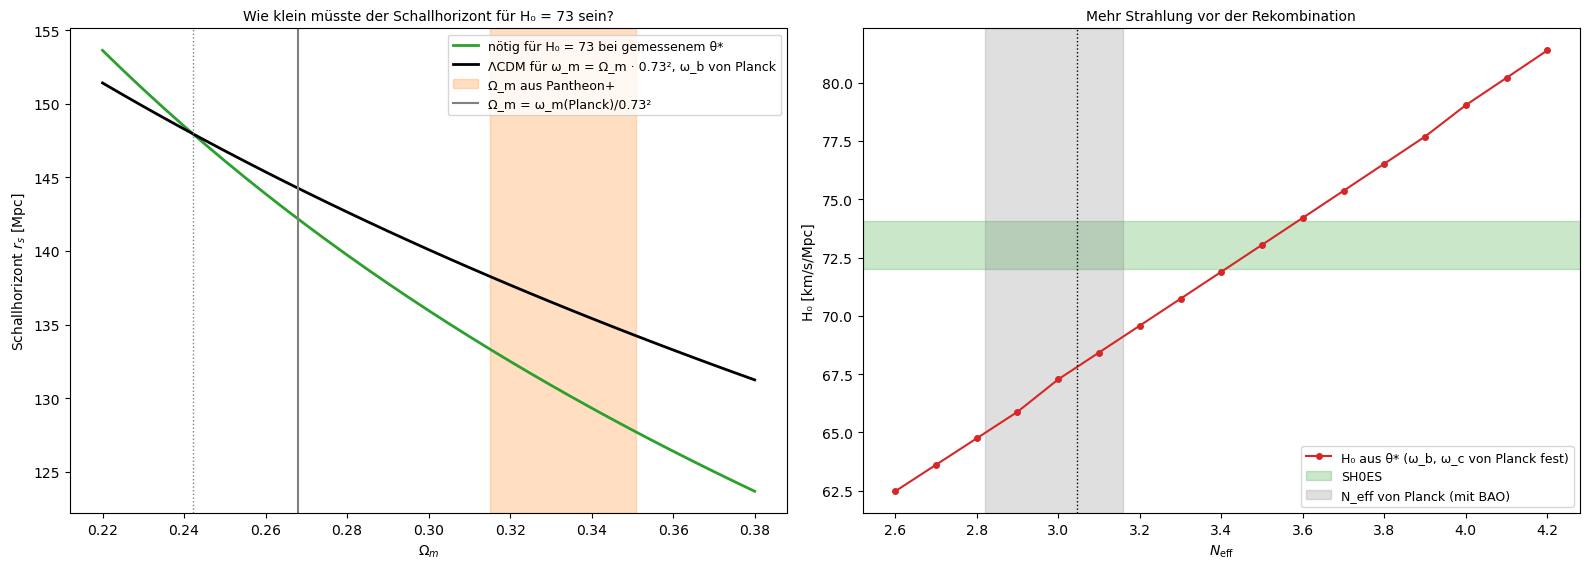

H₀ = 73 passt in ΛCDM zu θ* bei Ω_m = 0.242 (ω_m = 0.1292; Planck 0.143)
bei Ω_m = 0.333 aus Pantheon+: r_s nötig 130.4 Mpc, ΛCDM gibt 136.2 Mpc (-4.3 %)
Ω_m = 0.242 liegt 5.0 σ unter Pantheon+
mit ω_m von Planck: Ω_m = 0.268 (3.6 σ unter Pantheon+), r_s nötig 142.2 statt 144.3 Mpc (-1.5 %)
Ω_m = 0.333 und H₀ = 73 verlangen ω_m = 0.1777, 24 % mehr als Planck aus den Peakhöhen
N_eff für H₀ = 73: 3.50, also 3.0 σ über dem Wert von Planck; r_s dann 142.1 Mpc


In [16]:
h73 = H0_SH0ES[0] / 100
oms = np.linspace(0.22, 0.38, 33)
rs_need, rs_lcdm = [], []
for o in oms:
    a = acoustic(h73, wb0, o * h73**2)
    rs_lcdm.append(a["rs"])
    rs_need.append(THETA_FIT[0] / 100 * a["dm"])
rs_need, rs_lcdm = np.array(rs_need), np.array(rs_lcdm)
om_cross = np.interp(0, rs_lcdm - rs_need, oms)
need_sn = np.interp(OM_SN[0], oms, rs_need)
lcdm_sn = np.interp(OM_SN[0], oms, rs_lcdm)
om_wm = wm0 / h73**2
need_wm, lcdm_wm = np.interp(om_wm, oms, rs_need), np.interp(om_wm, oms, rs_lcdm)
neffs = np.linspace(2.6, 4.2, 17)
h_neff = np.array([100 * h_from_theta(THETA_FIT[0], wb0, wm0, neff=x) for x in neffs])
neff_73 = np.interp(H0_SH0ES[0], h_neff, neffs)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 5.8))
ax.plot(oms, rs_need, color="C2", lw=2, label="nötig für H₀ = 73 bei gemessenem θ*")
ax.plot(oms, rs_lcdm, color="k", lw=2, label="ΛCDM für ω_m = Ω_m · 0.73², ω_b von Planck")
ax.axvspan(OM_SN[0] - OM_SN[1], OM_SN[0] + OM_SN[1], color="C1", alpha=0.25, label="Ω_m aus Pantheon+")
ax.axvline(om_cross, color="0.5", ls=":", lw=1)
ax.axvline(om_wm, color="0.5", lw=1.5, label="Ω_m = ω_m(Planck)/0.73²")
ax.set_xlabel(r"$\Omega_m$")
ax.set_ylabel(r"Schallhorizont $r_s$ [Mpc]")
ax.set_title("Wie klein müsste der Schallhorizont für H₀ = 73 sein?", fontsize=10)
ax.legend(fontsize=9)
ax2.plot(neffs, h_neff, "o-", color="C3", ms=4, label="H₀ aus θ* (ω_b, ω_c von Planck fest)")
ax2.axhspan(H0_SH0ES[0] - H0_SH0ES[1], H0_SH0ES[0] + H0_SH0ES[1], color="C2", alpha=0.25, label="SH0ES")
ax2.axvspan(NEFF_PLANCK[0] - NEFF_PLANCK[1], NEFF_PLANCK[0] + NEFF_PLANCK[1], color="0.5", alpha=0.25,
            label="N_eff von Planck (mit BAO)")
ax2.axvline(3.046, color="k", ls=":", lw=1)
ax2.set_xlabel(r"$N_\mathrm{eff}$")
ax2.set_ylabel("H₀ [km/s/Mpc]")
ax2.set_title("Mehr Strahlung vor der Rekombination", fontsize=10)
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(f"H₀ = 73 passt in ΛCDM zu θ* bei Ω_m = {om_cross:.3f} (ω_m = {om_cross * h73**2:.4f}; Planck {PLANCK['wm'][0]})")
print(f"bei Ω_m = {OM_SN[0]} aus Pantheon+: r_s nötig {need_sn:.1f} Mpc, ΛCDM gibt {lcdm_sn:.1f} Mpc ({100 * (need_sn / lcdm_sn - 1):+.1f} %)")
print(f"Ω_m = {om_cross:.3f} liegt {(OM_SN[0] - om_cross) / OM_SN[1]:.1f} σ unter Pantheon+")
print(f"mit ω_m von Planck: Ω_m = {om_wm:.3f} ({(OM_SN[0] - om_wm) / OM_SN[1]:.1f} σ unter Pantheon+), r_s nötig {need_wm:.1f} statt {lcdm_wm:.1f} Mpc ({100 * (need_wm / lcdm_wm - 1):+.1f} %)")
print(f"Ω_m = {OM_SN[0]} und H₀ = 73 verlangen ω_m = {OM_SN[0] * h73**2:.4f}, {100 * (OM_SN[0] * h73**2 / wm0 - 1):.0f} % mehr als Planck aus den Peakhöhen")
print(f"N_eff für H₀ = 73: {neff_73:.2f}, also {(neff_73 - NEFF_PLANCK[0]) / NEFF_PLANCK[1]:.1f} σ über dem Wert von Planck; "
      f"r_s dann {acoustic(h73, wb0, wm0, neff=neff_73)['rs']:.1f} Mpc")

* Links zwei Schallhorizonte als Funktion von Ω_m: grün der, den H₀ = 73 bei gemessenem $\theta_\star$ verlangt, schwarz der, den ΛCDM für dieselben Dichten liefert. Sie treffen sich nur bei Ω_m = 0.242 (ω_m = 0.129). Das liegt 5.0σ unter Pantheon+ und 10 % unter dem ω_m von Planck.
* Zwei weitere Fälle:
  - **ω_m von Planck** (graue Linie, Ω_m = 0.268): r_s müsste um 1.5 % schrumpfen, von 144.3 auf 142.2 Mpc. Dann liegt Ω_m aber 3.6σ unter Pantheon+.
  - **Ω_m = 0.333 aus Pantheon+:** H₀ = 73 verlangt ein ω_m von 0.178, 24 % mehr als die Peakhöhen erlauben, und trotzdem ein um 4.3 % kleineres r_s.
* Rechts H₀ aus $\theta_\star$ gegen N_eff bei festen ω_b und ω_c. Jede zusätzliche Neutrinoart hebt H₀ um etwa 11 km/s/Mpc. Für 73 genügt N_eff = 3.50, das verkleinert r_s auf 142.1 Mpc. Planck misst aber 2.99 ± 0.17, 3.0σ weniger, und zwar über den Dämpfungsschwanz, den diese Rechnung nicht enthält. Zur Vorhersage: 1 % reicht nicht ganz, bei festem ω_m sind 1.5 % nötig. Das klingt wenig, aber jede Änderung, die r_s verkleinert, muss zugleich die Peakhöhen, den Dämpfungsschwanz und die Supernovae in Ruhe lassen. Darum ist die Spannung so hartnäckig.

[↑ Zurück zur Landkarte](#landkarte)

#### **Ergebnis**

Beim Lauf vom 2026-11-08 (Planck-Karten PR3 bei 100 und 143 GHz in vier Feldern von 20°, Spektrum PR3 von Planck, Rechnung ohne Boltzmann-Code):

- **Eigene Karten:** Die Flecken sind bei 100 und 143 GHz dieselben (Korrelation 0.975 bis 0.980, halbe Differenz 10 bis 13 μK gegen 96 bis 113 μK). Das Kreuzspektrum der vier Felder zeigt die ersten drei Peaks deutlich. Ein Fit mit Amplitude, Punktquellen und Streckung gibt A = 1.000 ± 0.012 und **100 $\theta_\star$ = 1.0434 ± 0.0029** (χ² = 25.7 bei 26), 0.8σ neben Planck. Dafür mussten neun helle Quellen und die Lücken von SkyView an den Polen ersetzt werden.
- **Peaks:** Die ersten fünf Peaks liegen bei ℓ = 221, 534, 815, 1122 und 1417 (je ±3), mit H₂ = 0.452 ± 0.006 und H₃ = 0.443 ± 0.005. Die Gerade ℓ_A (n − φ) gibt ℓ_A = 298.0 ± 1.1; roh folgt 100 $\theta_\star$ = 1.054, am Modell geeicht 1.0458 ± 0.0038.
- **$\theta_\star$:** Der Schablonen-Fit über alle ℓ gibt **100 $\theta_\star$ = 1.04116 ± 0.00045**, 0.3σ neben Planck TT+lowE (1.04097 ± 0.00046).
- **Schallhorizont:** r_s = 144.26 Mpc und $z_\star$ = 1091.9 mit der Näherung von Hu & Sugiyama; mit dem $z_\star$ von Planck genau 144.43 Mpc wie bei Planck. Ohne Baryonen wäre r_s 12 % größer.
- **Dichten:** Aus den Peakhöhen folgen ω_b = 0.0229 ± 0.0007 und ω_m = 0.140 ± 0.003 (Planck 0.0224 und 0.143). Die Formeln von Hu et al. liegen am besten Modell um 1.5 bis 1.8 % daneben.
- **H₀:**
  - 69.7 ± 1.7 aus dem Spektrum allein;
  - 70.4 ± 1.9 mit $\theta_\star$ aus den eigenen Karten;
  - **66.7 ± 1.1 mit Ω_m aus Pantheon+**, 4.2σ unter SH0ES;
  - 67.8 mit den Dichten von Planck (Planck selbst: 67.36 ± 0.54).
- **Was sich ändern müsste:** Mit dem ω_m von Planck müsste r_s um 1.5 % kleiner sein; dann wäre Ω_m = 0.27, 3.6σ unter Pantheon+. Mit Ω_m aus Pantheon+ bräuchte H₀ = 73 24 % mehr Materie, als die Peakhöhen erlauben. Zusätzliche Strahlung mit N_eff = 3.5 würde reichen, liegt aber 3σ über dem Wert von Planck.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und das Notebook neu ausführen:

1. **Die Lücken an den Polen nicht füllen:** in `fill_gaps` die Zeile `bad = x == 0` durch `bad = x == 1e30` ersetzen. *(Vorhersage: Eine Spalte aus Nullen ist eine scharfe Linie in der Karte und verteilt Leistung über alle ℓ, am stärksten dort, wo das Signal schwach ist. Bis ℓ = 1200 ändert sich wenig, α wird 1.0016 statt 1.0022. Im Fit bis ℓ = 2000 steigt χ² aber von 40.8 auf 62.6 und P von 123 auf 243 μK². Die Simulationen in Schritt 5 hätten das nicht gezeigt, weil sie keine Lücken haben.)*
2. **Ein breiterer Rand des Fensters:** `taper(n=NPIX, frac=0.25)` statt 0.125. *(Vorhersage: Das Fenster lässt weniger Fläche übrig, der Fehler von $\theta_\star$ wächst von 0.0029 auf 0.0033; der Wert bleibt bei 100 $\theta_\star$ = 1.0436.)*
3. **Die Punktquellen nicht ersetzen:** in Schritt 6 `CLEAN` durch `MAPS` ersetzen. *(Vorhersage: P steigt von 193 auf 264 μK², $\theta_\star$ bleibt fast gleich (1.0428 statt 1.0434). Die Quellen ändern die Leistung bei großen ℓ, nicht die Lage der Peaks.)*
4. **Nur drei Peaks für den Abstand:** `PEAKS` auf die ersten drei Einträge kürzen. *(Vorhersage: ℓ_A wird 297.2, der Fehler des geeichten $\theta_\star$ verdoppelt sich auf 0.0074 (100 $\theta_\star$ = 1.0389). Die höheren Peaks verlängern den Hebel der Geraden.)*
5. **Das $z_\star$ von Planck statt der Näherung:** in `acoustic` die Zeile `zs = z_star(wb, wm) if zs is None else zs` durch `zs = 1089.92 if zs is None else zs` ersetzen. *(Vorhersage: Weg A gibt 67.38 statt 67.80, fast genau den Wert von Planck (67.36); B wird 69.47 und C 66.57. Der Rest der Rechenkette stimmt also, die 0.4 km/s/Mpc kamen nur aus $z_\star$.)*
6. **Ein anderer Spektralindex:** `NS = 0.975` statt 0.9649. *(Vorhersage: Ein steileres Spektrum der Anfangsschwankungen hebt die höheren Peaks an. Die Formeln schreiben das den Dichten zu: ω_b = 0.0232, ω_m = 0.137, und H₀ aus Weg B steigt von 69.7 auf 71.0. Deshalb fittet Planck n_s zusammen mit allen anderen Parametern.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum sind die Flecken bei 100 und 143 GHz gleich stark, Staub aber nicht?</summary>

Die Karten sind in K_CMB geeicht: Eine kleine Änderung der Temperatur eines Schwarzkörpers ergibt bei jeder Frequenz dieselbe Zahl. Staub hat ein anderes Spektrum, seine Intensität steigt mit der Frequenz stark an. In K_CMB ist er deshalb bei 143 GHz heller als bei 100 GHz.
</details>

<details><summary>2. Was ist D_ℓ, und welcher Fleckengröße entspricht ℓ = 220?</summary>

$D_\ell = \ell(\ell+1)C_\ell/2\pi$ ist der Beitrag einer logarithmischen Bandbreite um ℓ zur Varianz der Karte, in μK². ℓ = 220 gehört nach θ ≈ 180°/ℓ zu Flecken von knapp 1°.
</details>

<details><summary>3. Warum kennt man C₁₀ nie genauer als auf etwa 30 %?</summary>

Zu ℓ = 10 gibt es nur 2ℓ + 1 = 21 Werte $a_{\ell m}$ am ganzen Himmel. Ihre Varianz ist aus 21 Zahlen nur auf $\sqrt{2/21} = 0.31$ genau zu schätzen. Das ist die kosmische Varianz: Wir haben nur ein Universum.
</details>

<details><summary>4. Warum hat das Kreuzspektrum von 100 und 143 GHz keinen Rauschbias?</summary>

Das Rauschen der beiden Karten stammt aus verschiedenen Detektoren und ist unabhängig. Im Mittel ist das Produkt der beiden Rauschanteile null; übrig bleibt nur das gemeinsame Signal, gedämpft mit $B_\ell^{100}B_\ell^{143}$.
</details>

<details><summary>5. Was passiert mit dem Rauschen, wenn man durch B_ℓ² teilt?</summary>

Es wird genauso verstärkt wie das Signal, aber das Rauschen ist vor dem Teilen flach in ℓ. Nach dem Teilen wächst es exponentiell mit ℓ², bei 100 GHz am stärksten, weil der Strahl dort breiter ist.
</details>

<details><summary>6. Warum wächst der Beitrag von Punktquellen wie ℓ²?</summary>

Zufällig verteilte Punkte haben ein flaches Leistungsspektrum, $C_\ell$ = konstant (Poisson-Rauschen). Mit $D_\ell \propto \ell(\ell+1)C_\ell$ wächst ihr Beitrag deshalb wie ℓ², während die Hintergrundstrahlung durch die Silk-Dämpfung abfällt.
</details>

<details><summary>7. Was prüfen die Simulationen in Schritt 5, und was prüfen sie nicht?</summary>

Sie prüfen das Verfahren: Fenster, Strahl, Pixel und Mittelung in Ringen geben ein bekanntes Spektrum unverzerrt zurück, und die Streuung passt zur kosmischen Varianz. Fehler in den Daten selbst prüfen sie nicht, etwa die Lücken, die SkyView an den Polen lässt. Die fand erst der Blick auf die Karte.
</details>

<details><summary>8. Was ist der Schallhorizont, und warum hängt er nicht von H₀ ab?</summary>

Er ist die mitbewegte Strecke, die eine Schallwelle im Plasma vom Urknall bis zur Rekombination zurücklegen konnte, $r_s = \int c_s\,dz/H$. Vor der Rekombination legen nur die physikalischen Dichten $\omega_b$, $\omega_m$ und $\omega_r$ die Expansion fest. Die Dunkle Energie, über die $h$ bei festem $\omega_m$ eingeht, spielt damals keine Rolle.
</details>

<details><summary>9. Warum machen mehr Baryonen den zweiten Peak im Vergleich zum ersten kleiner?</summary>

Baryonen machen die Photon-Baryon-Flüssigkeit schwerer und verschieben ihr Gleichgewicht in den Potentialtöpfen zur Verdichtung hin. Die Verdichtungen (ungerade Peaks) werden stärker, die Verdünnungen (gerade Peaks) schwächer.
</details>

<details><summary>10. Warum gibt π/ℓ_A ein zu großes $\theta_\star$?</summary>

Die Peaks liegen nicht genau bei Vielfachen von ℓ_A. Zerfallende Potentiale treiben die Schwingungen an und verschieben ihre Phase, und Baryonen verschieben gerade und ungerade Peaks verschieden. Eine Gerade durch die Peaks hat deshalb eine etwas andere Steigung als π/$\theta_\star$; am Modell sind es 0.83 %. Man eicht das Verfahren am Modell, dessen $\theta_\star$ man kennt.
</details>

<details><summary>11. Warum wird ein Fehler in $\theta_\star$ in H₀ etwa fünfmal größer?</summary>

Bei festen Dichten hängt $\theta_\star$ nur über $D_M$ und die Dunkle Energie von h ab, schwach, etwa wie $h^{0.2}$. Umgekehrt ist dann $h \propto \theta_\star^5$, und ein Fehler von 0.1 % in $\theta_\star$ wird zu 0.5 % in H₀.
</details>

<details><summary>12. Was heißt es, dass $\theta_\star$ eine Linie in der Ebene von Ω_m und H₀ festlegt?</summary>

Bei festem ω_b gibt es zu jedem Ω_m genau ein H₀, das das gemessene $\theta_\star$ ergibt; entlang dieser Linie ist $\Omega_m h^3$ fast konstant. Erst eine zweite Messung legt den Punkt fest: die Peakhöhen (ω_m) oder die Form des Hubble-Diagramms der Supernovae (Ω_m).
</details>

<details><summary>13. Warum reicht es nicht, einfach Ω_m = 0.24 zu nehmen, damit H₀ = 73 herauskommt?</summary>

Dann widerspricht man zwei anderen Messungen. Die Supernovae von Pantheon+ messen Ω_m = 0.333 ± 0.018, 5σ mehr, und die Peakhöhen verlangen ω_m ≈ 0.14, nicht 0.129. Jede Lösung der Spannung muss $\theta_\star$, die Peakhöhen und die Supernovae zugleich erfüllen.
</details>

<details><summary>14. Was könnte den Schallhorizont verkleinern, und warum ist das schwer?</summary>

Eine schnellere Expansion vor der Rekombination, durch zusätzliche Strahlung ($N_\text{eff} > 3.046$) oder eine frühe Dunkle Energie. Beides ändert aber auch den Dämpfungsschwanz und die Peakhöhen. Planck misst $N_\text{eff} = 2.99 \pm 0.17$, und frühe Dunkle Energie verlangt mehr Dunkle Materie, was andere Messungen der Strukturbildung stört.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Ein Boltzmann-Code statt Näherungsformeln:** CAMB oder CLASS rechnen das ganze Spektrum für gegebene Parameter. Ein MCMC-Fit (etwa mit Cobaya) aller sechs Parameter an die Likelihood von Planck ersetzt die Formeln von Hu et al. mit ihren 1.5 bis 1.8 % Fehler und das genäherte $z_\star$.
- **Der ganze Himmel:** HEALPix-Karten mit healpy und einer Maske der Milchstraße statt vier Feldern. Dazu ein Pseudo-$C_\ell$-Verfahren (MASTER, NaMaster), das die Kopplung der Multipole durch die Maske herausrechnet. Mehr Himmel heißt kleinere kosmische Varianz.
- **Polarisation:** Die Spektren TE und EE haben Peaks, die gegen TT um eine halbe Periode verschoben sind und schärfer sind. Planck, ACT und SPT gewinnen daraus einen großen Teil ihrer Genauigkeit.
- **Der Dämpfungsschwanz:** Das Verhältnis der Silk-Dämpfungslänge zum Schallhorizont misst die Strahlung vor der Rekombination, also N_eff. Die Messungen von ACT und SPT bei ℓ > 2000 schränken frühe Lösungen der Spannung damit stark ein.
- **Derselbe Maßstab in den Galaxien:** Der Schallhorizont steckt auch als baryonische akustische Oszillation in der Verteilung der Galaxien. DESI misst damit Entfernungen bis z ≈ 2; zusammen mit $\theta_\star$ oder ω_b aus der Nukleosynthese gibt das H₀ ohne Cepheiden (inverse Entfernungsleiter).

#### **Referenzen**

- Dodelson, S. & Schmidt, F. (2020): *Modern Cosmology*, 2. Aufl., Academic Press, Kap. 8 und 9 (Anisotropien der Hintergrundstrahlung, Leistungsspektrum).
- Hu, W. & Dodelson, S. (2002): *Cosmic Microwave Background Anisotropies*, ARA&A 40, 171 (akustische Peaks, Baryonen, Dämpfung).
- Hu, W. & Sugiyama, N. (1996): *Small-scale cosmological perturbations: an analytic approach*, ApJ 471, 542 (Gl. E1, $z_\star$).
- Hu, W., Fukugita, M., Zaldarriaga, M. & Tegmark, M. (2001): *CMB observables and their cosmological implications*, ApJ 549, 669 (Gl. A7, A19, A21).
- Knox, L. (1995): *Determination of inflationary observables by cosmic microwave background anisotropy experiments*, Phys. Rev. D 52, 4307 (Fehler eines Spektrums).
- Calabretta, M. R. & Greisen, E. W. (2002): *Representations of celestial coordinates in FITS*, A&A 395, 1077 (Projektionen TAN und ARC).
- Górski, K. M. et al. (2005): *HEALPix: a framework for high-resolution discretization and fast analysis of data distributed on the sphere*, ApJ 622, 759.
- Planck Collaboration (2020): *Planck 2018 results. III. High Frequency Instrument data processing and frequency maps*, A&A 641, A3.
- Planck Collaboration (2020): *Planck 2018 results. V. CMB power spectra and likelihoods*, A&A 641, A5.
- Planck Collaboration (2020): *Planck 2018 results. VI. Cosmological parameters*, A&A 641, A6 (Tabelle 2).
- Riess, A. G. et al. (2022): *A comprehensive measurement of the local value of the Hubble constant with 1 km/s/Mpc uncertainty from the Hubble Space Telescope and the SH0ES team*, ApJL 934, L7.
- Knox, L. & Millea, M. (2020): *Hubble constant hunter's guide*, Phys. Rev. D 101, 043533 (warum Lösungen der Spannung den Schallhorizont ändern müssen).
- Poulin, V., Smith, T. L., Karwal, T. & Kamionkowski, M. (2019): *Early dark energy can resolve the Hubble tension*, Phys. Rev. Lett. 122, 221301.